# Listings: Modelo Supervisado de Precio y Evaluación de PCA

Continuación del pipeline de las entregas 1 y 2 sobre los anuncios de Airbnb en Ciudad de México (Inside Airbnb,
scrape del 25 de junio al 2 de julio de 2025). El punto de partida es la capa gold que dejó el EDA
(`data/gold/listings_encoded.csv`).

**Pregunta del notebook:** ¿qué tan bien se puede estimar el precio por noche de un anuncio a partir de sus características,
y conviene reducir las variables con PCA antes de modelar?

**Para qué sirve el modelo:**

1. Sugerir un precio de referencia a un anfitrión, según lo que cobra el mercado por un anuncio parecido.
2. Señalar anuncios cuyo precio se aleja mucho del esperado, para revisarlos.
3. Cuantificar qué características pesan más en el precio.

**Estructura:**

- **1.** Carga de datos.
- **2.** Revisión de calidad: ¿hace falta más limpieza?
- **3.** Definición del problema, variables y partición.
- **4.** Modelos sin PCA.
- **5.** Análisis de PCA: ¿es necesario y con cuántas variables?
- **6.** Evaluación final en el conjunto de prueba.
- **7.** Diagnóstico del modelo.
- **8.** Conclusiones.

**Resultado principal:** PCA no es necesario. El modelo final es HistGradientBoosting con las 67 variables, sin PCA:
en prueba obtiene R² = 0.711 en escala logarítmica y un error porcentual mediano de 22.7%. Con PCA reajustado y 59 componentes,
su error (RMSE) sube 12.4% en prueba.

Se ejecuta de arriba a abajo y tarda unos 10 minutos. Las figuras se exportan a `reports/figures/modelo`.

In [1]:
import contextlib
import io
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, make_scorer,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import (GridSearchCV, GroupKFold, GroupShuffleSplit, KFold,
                                     RandomizedSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
matplotlib.rcParams["figure.dpi"] = 110
matplotlib.rcParams["axes.titleweight"] = "bold"

# Misma paleta de las entregas anteriores; cada modelo conserva su color en todas las figuras
AZUL, AZUL_CLARO, ACENTO, GRIS, VERDE = "steelblue", "skyblue", "firebrick", "#6b6b6b", "seagreen"
COLOR_MODELO = {"Ridge": AZUL, "Random Forest": VERDE, "HistGradientBoosting": ACENTO}

SEMILLA = 42
FIG = Path("../reports/figures/modelo")
FIG.mkdir(parents=True, exist_ok=True)


def guardar(fig, nombre):
    """Exporta la figura a reports/figures/modelo con resolución de informe."""
    fig.savefig(FIG / nombre, bbox_inches="tight", dpi=150)

## 1. Carga de datos

El insumo es la capa gold de la entrega 2: 26,322 anuncios y 67 columnas, todas numéricas. Como `data/silver/*.csv` y
`data/gold/*.csv` están en el `.gitignore`, la celda revisa si existen y, si faltan, ejecuta `notebook/02_eda_listings.ipynb`,
que a su vez genera la capa silver con `notebook/listings_clean.ipynb`. Así el notebook funciona sobre un clon limpio.

Al gold le faltan columnas que este modelo necesita, y se recuperan de silver por `id`: `host_id` (para dividir los datos sin
fuga de información), `latitude` y `longitude`, `host_response_rate` y `host_acceptance_rate`.
`estimated_occupancy_l365d` se trae solo para la auditoría y **no** entra al modelo.

No existe la capa gold -> se ejecuta notebook/02_eda_listings.ipynb para generarla...


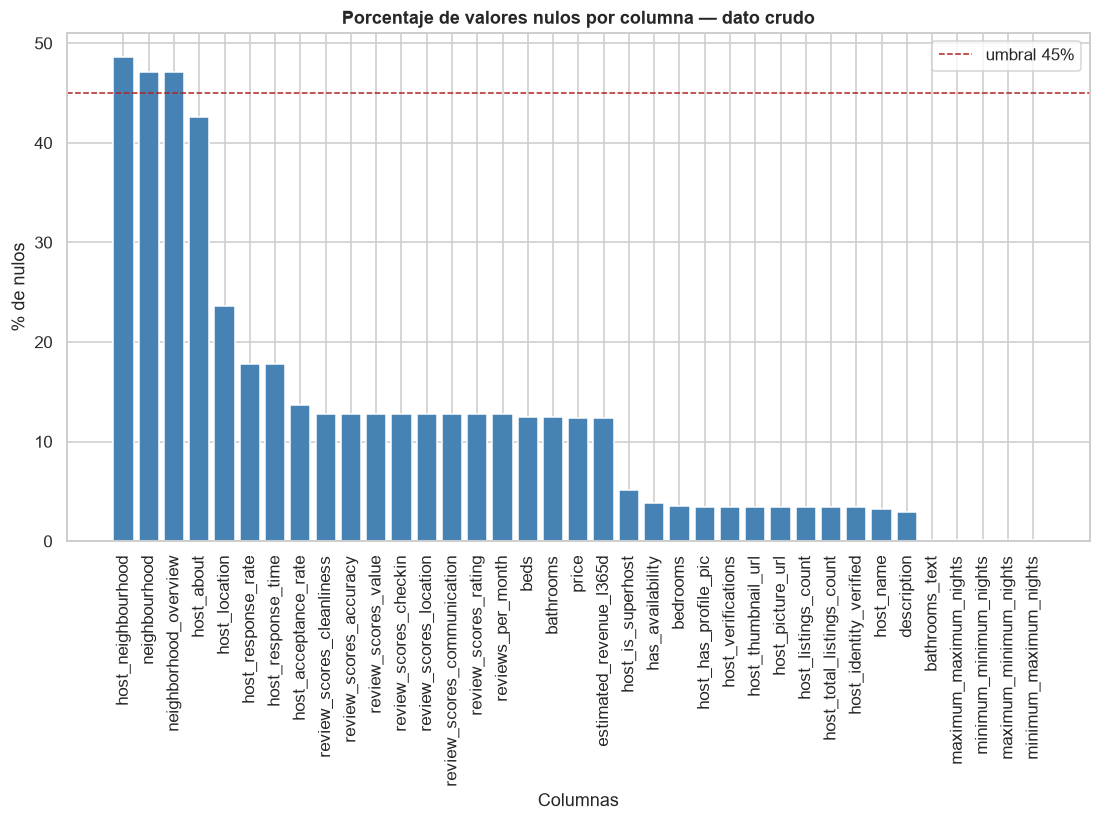

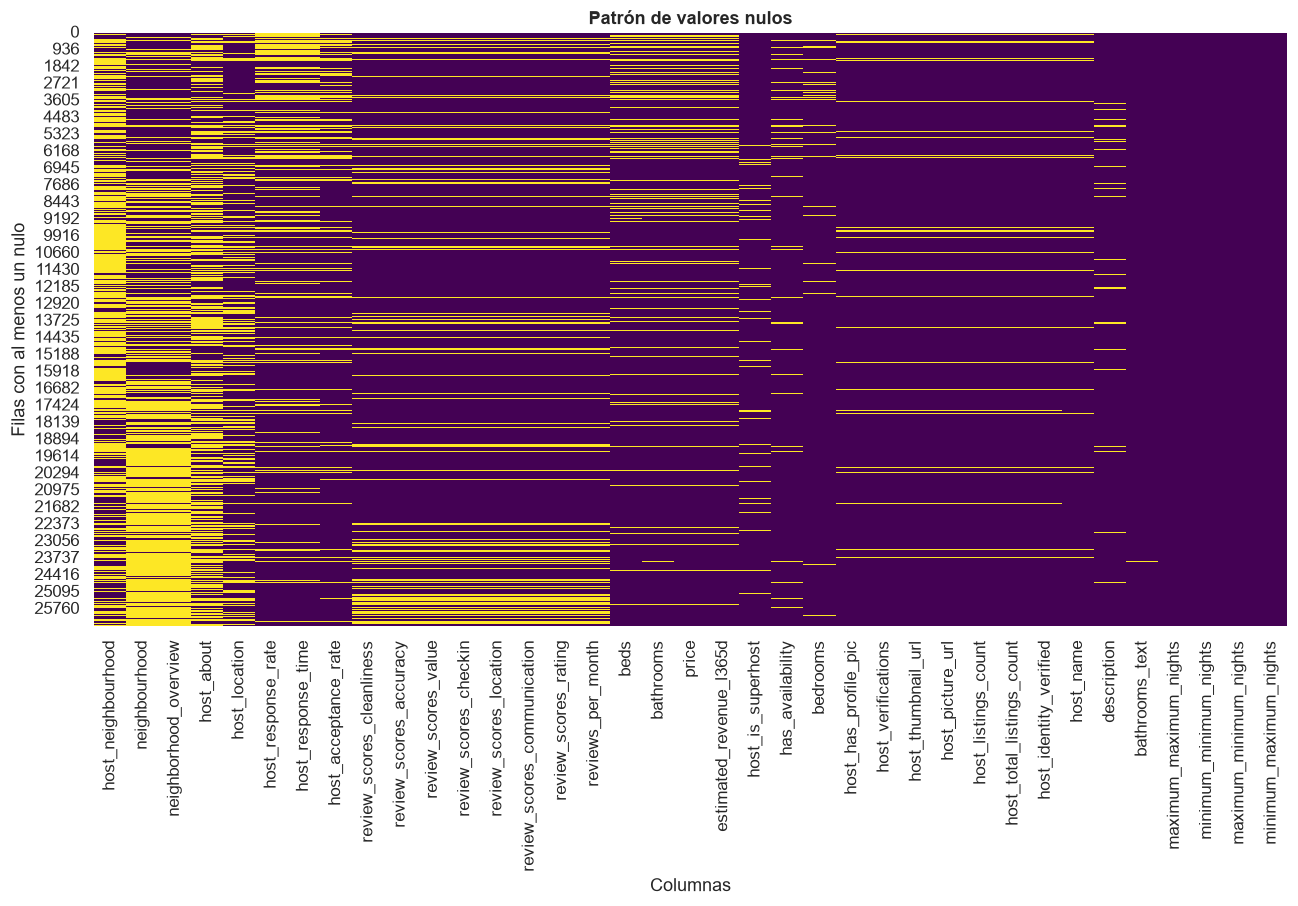

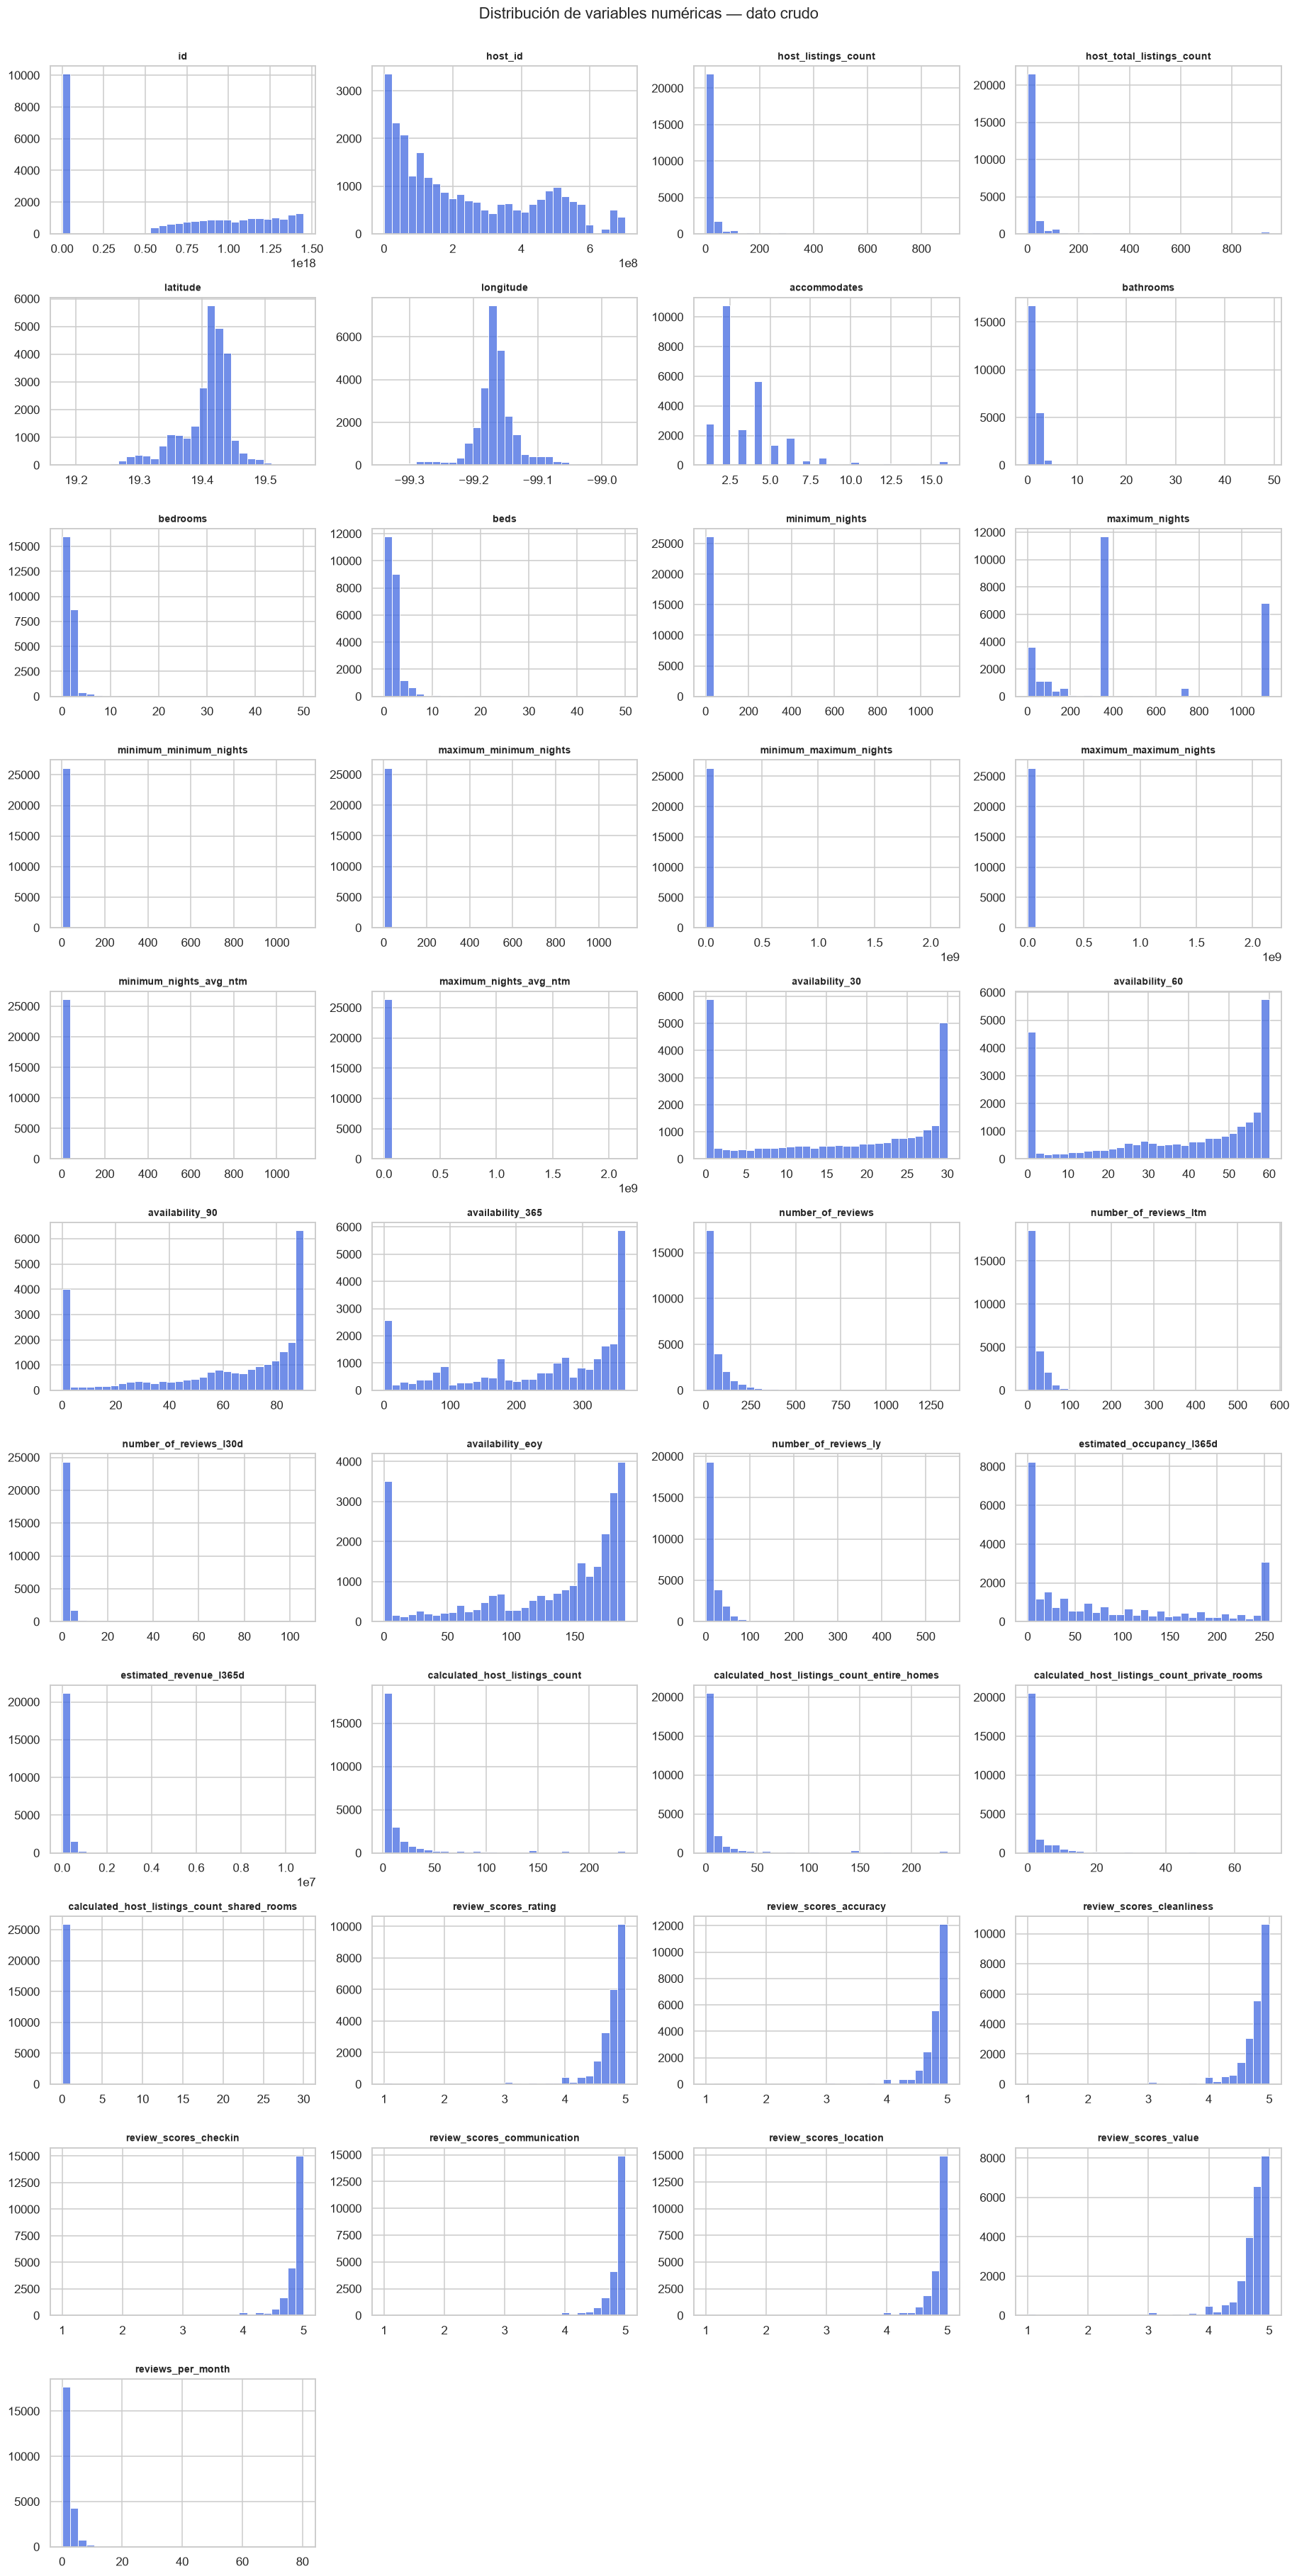

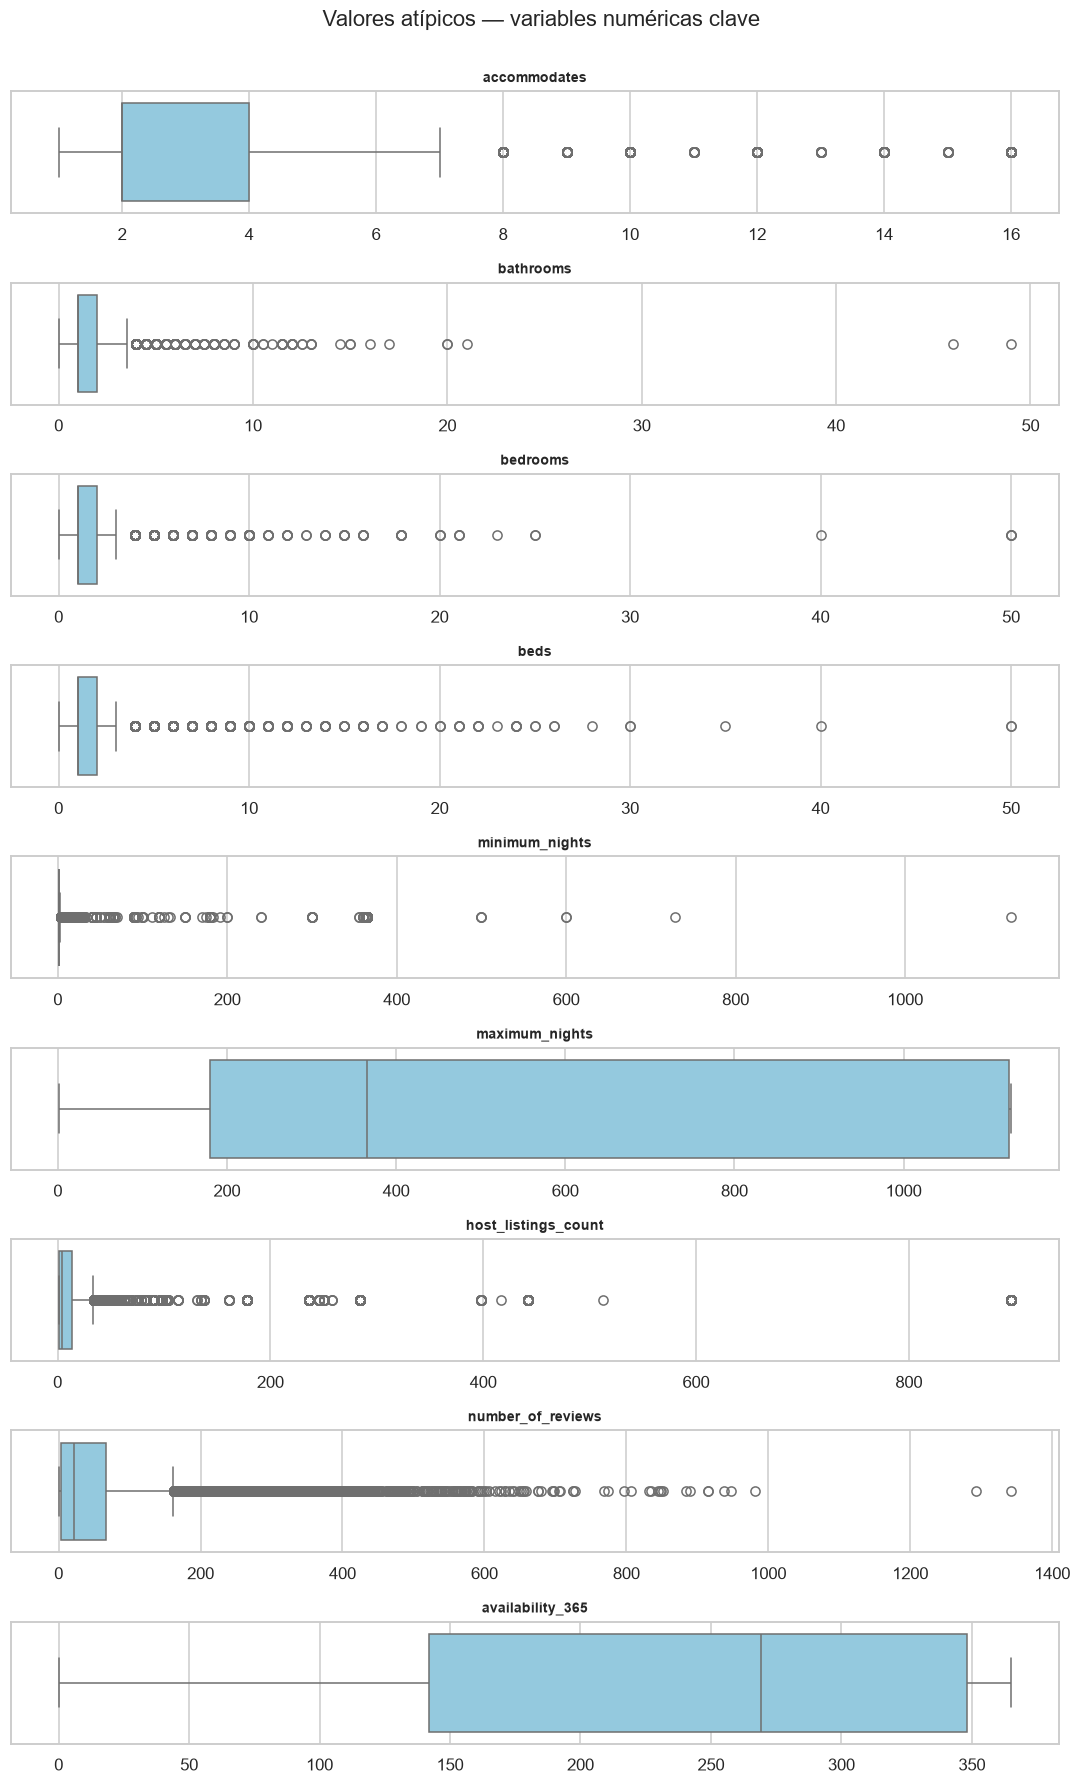

<string>:22: Pandas4Warning: reindexing with a fill_value that cannot be held by the original dtype is deprecated. Explicitly cast to a common dtype (in this case object) instead.


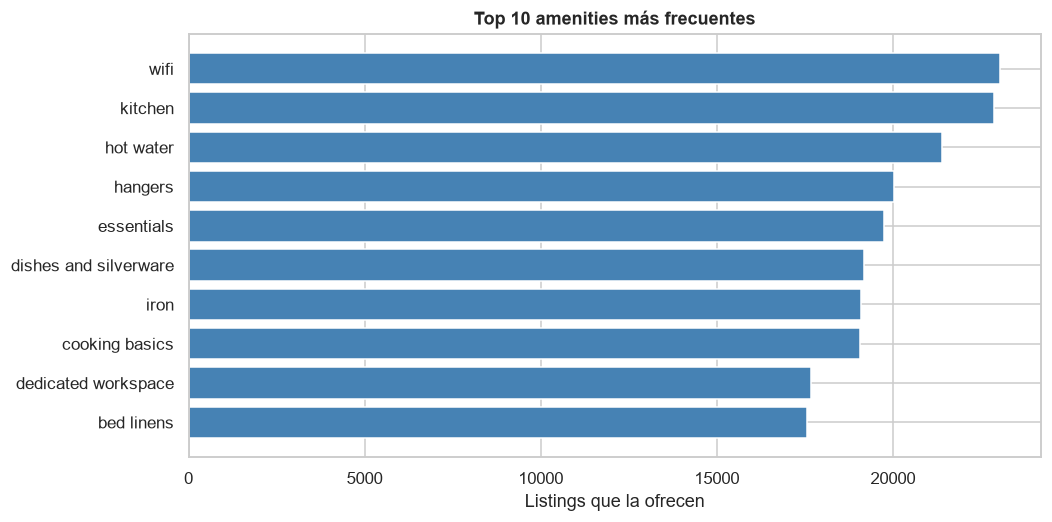

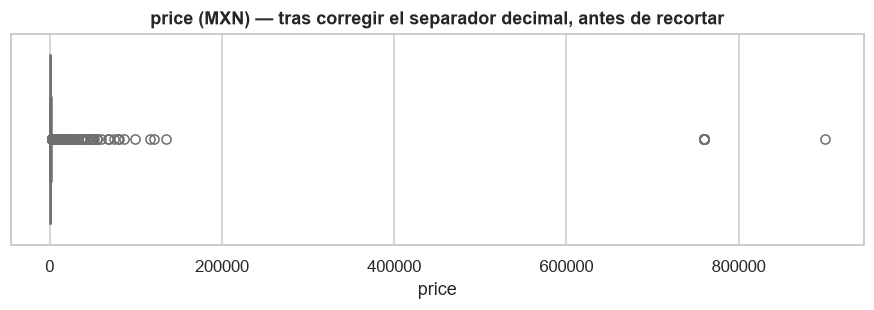

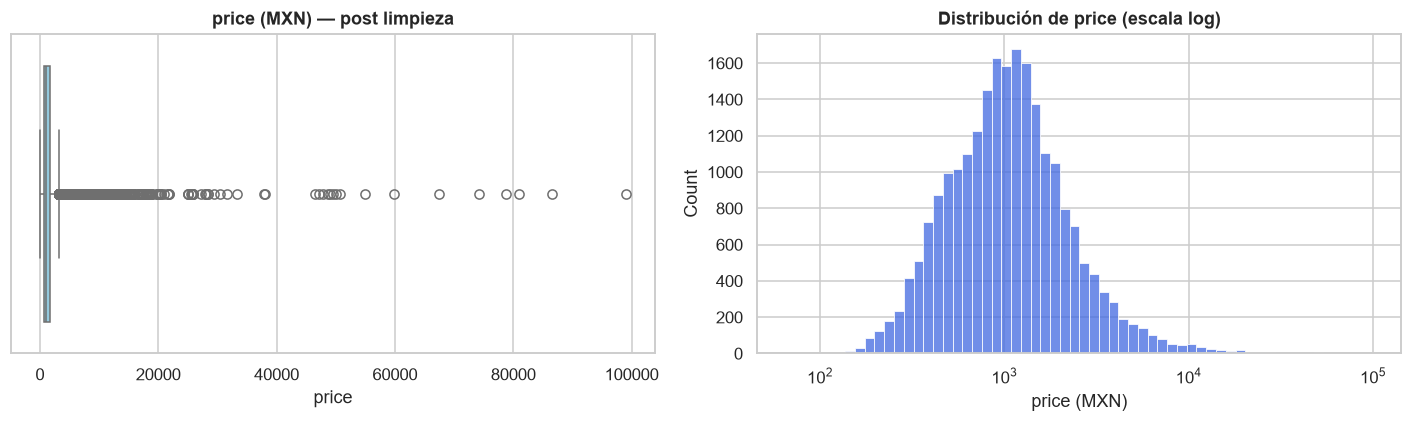

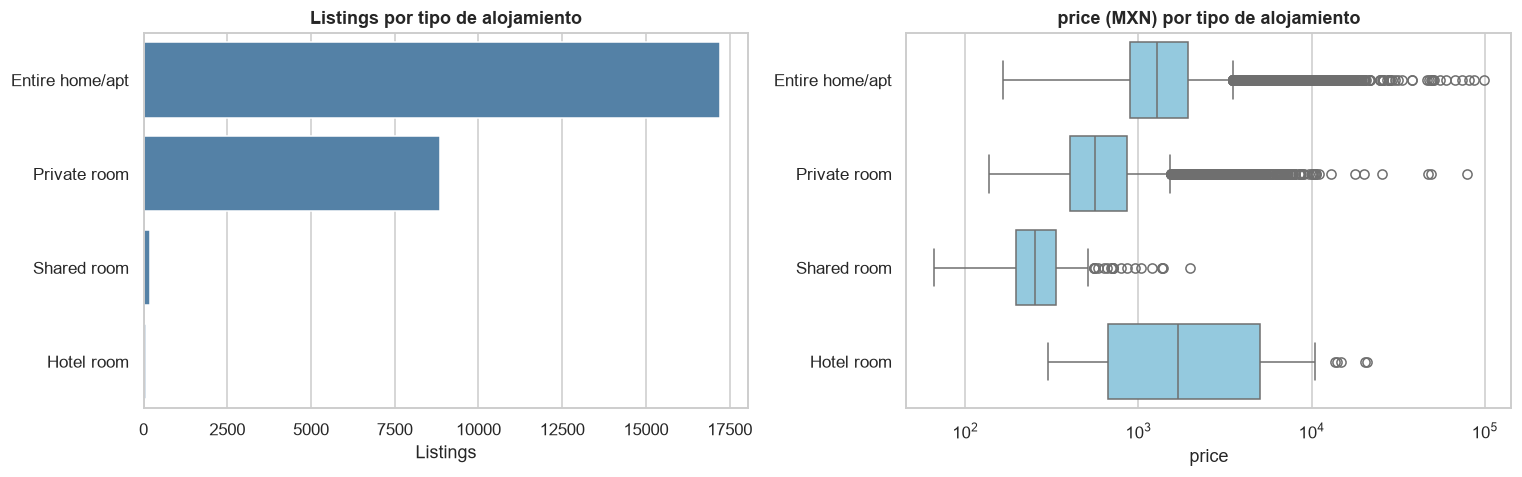

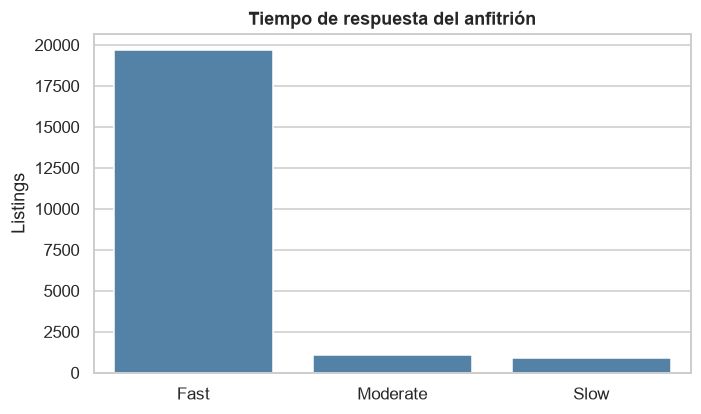

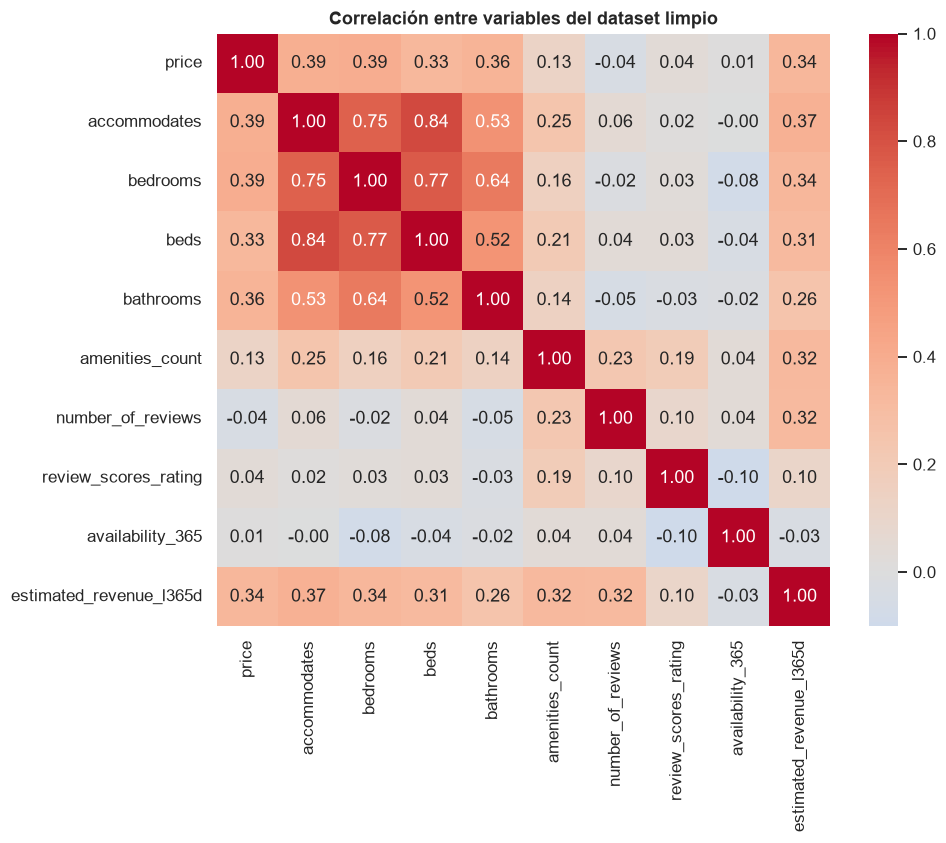

Capa gold generada.
Gold: 26,322 x 67 | tras unir con silver: 26,322 x 73


In [2]:
GOLD = Path("../data/gold/listings_encoded.csv")
SILVER = Path("../data/silver/listings.csv")

# data/silver y data/gold están en el .gitignore: si faltan se generan ejecutando la entrega 2,
# que a su vez ejecuta la entrega 1 si hace falta. Tarda alrededor de un minuto.
if not (GOLD.exists() and SILVER.exists()):
    print("No existe la capa gold -> se ejecuta notebook/02_eda_listings.ipynb para generarla...")
    nb_entrega2 = json.loads(Path("02_eda_listings.ipynb").read_text(encoding="utf-8"))
    entorno = {"display": lambda *args, **kwargs: None, "__name__": "__main__"}
    with contextlib.redirect_stdout(io.StringIO()):
        for celda in nb_entrega2["cells"]:
            if celda["cell_type"] == "code":
                codigo = "".join(celda["source"]).replace("plt.show()", "plt.close('all')")
                exec(codigo, entorno)
    plt.close("all")
    pd.set_option("display.float_format", lambda v: f"{v:,.4f}")   # la entrega 2 cambia este formato
    del nb_entrega2, entorno
    print("Capa gold generada.")

gold = pd.read_csv(GOLD, low_memory=False)
# Columnas que el gold no trae y que el modelo necesita: el anfitrión (para dividir sin fuga de
# información), las coordenadas y las tasas del anfitrión. La llave es el id del anuncio.
cols_silver = ["id", "host_id", "latitude", "longitude", "host_response_rate", "host_acceptance_rate",
               "estimated_occupancy_l365d"]
silver = pd.read_csv(SILVER, usecols=cols_silver, low_memory=False)
df = gold.merge(silver, on="id", how="left", validate="one_to_one")
assert df["host_id"].notna().all(), "Hay anuncios del gold sin correspondencia en silver"
print(f"Gold: {gold.shape[0]:,} x {gold.shape[1]} | tras unir con silver: {df.shape[0]:,} x {df.shape[1]}")

Se retiran los 3,265 anuncios sin precio. El EDA mostró que son anuncios inactivos en la fecha del scrape, y no se imputan porque
inventar la variable objetivo contaminaría el modelo.

In [3]:
sin_precio = df["price"].isna().sum()
df = df[df["price"].notna()].copy().reset_index(drop=True)
print(f"Anuncios sin precio retirados: {sin_precio:,} | quedan {len(df):,} de {df['host_id'].nunique():,} anfitriones")

Anuncios sin precio retirados: 3,265 | quedan 23,057 de 10,110 anfitriones


## 2. Revisión de calidad: ¿hace falta más limpieza?

La guía pide que la limpieza sea un proceso continuo. Antes de modelar se revisó el dataset con preguntas que importan
para un modelo y que las entregas anteriores no necesitaban responder.

In [4]:
precio_huesped = df["price"] / df["accommodates"]
es_cuarto = df["room_type_Entire home/apt"] == 0
verif_cero = df[["verif_email", "verif_phone", "verif_work_email"]].sum(axis=1) == 0
host_nulo = df["host_years"].isna()
sin_id = [c for c in df.columns if c != "id"]

auditoria = pd.DataFrame([
    ("Columnas derivadas del precio en el gold (fuga de información)",
     sum(c in gold.columns for c in ["estimated_revenue_l365d", "price_per_guest", "log_price", "outlier_price_iqr"])),
    ("is_has_availability con valor distinto de 1", int((df["is_has_availability"].dropna() != 1).sum())),
    ("beds == 0", int((df["beds"] == 0).sum())),
    ("bathrooms == 0", int((df["bathrooms"] == 0).sum())),
    ("bedrooms == 0 (estudios)", int((df["bedrooms"] == 0).sum())),
    ("Cuartos con bedrooms > accommodates", int((es_cuarto & (df["bedrooms"] > df["accommodates"])).sum())),
    ("Precio por huésped > $8,000", int((precio_huesped > 8000).sum())),
    ("Perfil de anfitrión ausente (host_years nulo)", int(host_nulo.sum())),
    ("  de ellos, con las 3 verificaciones en 0", int((host_nulo & verif_cero).sum())),
    ("Sin calificación (review_scores_rating nulo)", int(df["review_scores_rating"].isna().sum())),
    ("  de ellos, con 0 reseñas", int((df["review_scores_rating"].isna() & (df["number_of_reviews"] == 0)).sum())),
    ("availability_365 == 0", int((df["availability_365"] == 0).sum())),
    ("Filas idénticas salvo el id", int(df.duplicated(sin_id).sum())),
    ("Filas con igual anfitrión, coordenadas y precio", int(df.duplicated(["host_id", "latitude", "longitude", "price"]).sum())),
    ("reviews_per_month > 30", int((df["reviews_per_month"] > 30).sum())),
], columns=["revisión", "filas o columnas"]).set_index("revisión")
display(auditoria)

print("Precio mediano de los cuartos según bedrooms declarado:")
display(df[es_cuarto].groupby(df.loc[es_cuarto, "bedrooms"].clip(upper=5))["price"].agg(anuncios="count", mediana="median").round(0))

print("Percentiles del precio por huésped:")
display(precio_huesped.quantile([.5, .99, .995, .999, 1]).round(0).rename("MXN por huésped").to_frame())
extremos = df[precio_huesped > 8000]
print(f"Precio por huésped > $8,000: {len(extremos)} anuncios, {(extremos['estimated_occupancy_l365d'] == 0).sum()} sin ninguna noche ocupada estimada")
display(extremos.assign(precio_huesped=precio_huesped)[["id", "accommodates", "price", "precio_huesped", "number_of_reviews", "estimated_occupancy_l365d"]]
        .sort_values("price", ascending=False).head(8).round(0))

,filas o columnas
revisión,
Columnas derivadas del precio en el gold (fuga de información),0
is_has_availability con valor distinto de 1,0
beds == 0,361
bathrooms == 0,124
bedrooms == 0 (estudios),470
Cuartos con bedrooms > accommodates,123
"Precio por huésped > $8,000",24
Perfil de anfitrión ausente (host_years nulo),886
"de ellos, con las 3 verificaciones en 0",886


Precio mediano de los cuartos según bedrooms declarado:


,anuncios,mediana
bedrooms,,
0.0000,130,496.0000
1.0000,6941,550.0000
2.0000,228,810.0000
3.0000,79,800.0000
4.0000,38,659.0000
5.0000,35,627.0000


Percentiles del precio por huésped:


,MXN por huésped
0.5000,366.0000
0.9900,"2,180.0000"
0.9950,"3,233.0000"
0.9990,"8,018.0000"
1.0000,"49,500.0000"


Precio por huésped > $8,000: 24 anuncios, 20 sin ninguna noche ocupada estimada


,id,accommodates,price,precio_huesped,number_of_reviews,estimated_occupancy_l365d
16033,1106549995939886571,2,"99,000.0000","49,500.0000",6,0
4711,39693453,2,"81,000.0000","40,500.0000",10,0
20254,1334832217909613530,2,"78,841.0000","39,420.0000",7,42
3142,30043309,4,"74,237.0000","18,559.0000",1,0
8329,556592616972927168,3,"67,500.0000","22,500.0000",0,0
3343,31444436,4,"55,000.0000","13,750.0000",0,0
7708,53051606,2,"50,000.0000","25,000.0000",0,0
4221,36799468,6,"49,500.0000","8,250.0000",0,0


**Resultado de la auditoría: hace falta poca limpieza, y es puntual.** Cada punto sigue el formato de las entregas anteriores.

**a) Bandera sin variación: `is_has_availability`.**

- **Hallazgo:** solo toma el valor 1 (o nulo en 227 anuncios). Una columna constante no aporta información.
- **Transformación:** se elimina.

**b) Camas y baños en 0.**

- **Hallazgo:** 361 anuncios declaran 0 camas y 124 declaran 0 baños, aunque todos reciben huéspedes. Son datos sin capturar, no alojamientos sin camas.
- **Transformación:** pasan a nulo y se imputan dentro del pipeline. `bedrooms = 0` (470 anuncios) **no** se toca, porque es como
  Airbnb registra un estudio o loft.

**c) Recámaras que describen el edificio.**

- **Hallazgo:** 123 cuartos (privados, compartidos o de hotel) declaran más recámaras que huéspedes. La tabla confirma que en los
  cuartos el precio no sube de forma sostenida con las recámaras: \$810 con 2, \$800 con 3, \$659 con 4 y \$627 con 5 o más. El dato
  describe la casa, no lo que se renta; el EDA ya lo había advertido.
- **Transformación:** esos 123 valores pasan a nulo.

**d) Ceros falsos por perfil de anfitrión ausente.**

- **Hallazgo:** los 886 anuncios sin perfil de anfitrión tienen las tres verificaciones en 0. Ese 0 significa "no hay dato", no "no está verificado".
- **Transformación:** se crea la marca `host_sin_perfil`. Con el mismo criterio se crean `sin_resenas` (los 2,478 anuncios sin
  calificación son exactamente los que tienen 0 reseñas) y `sin_tasa_aceptacion`. Así el modelo distingue un valor imputado de uno real.

**e) Precios por huésped imposibles.**

- **Hallazgo:** el límite de \$100,000 de la entrega 1 mira el precio total, sin considerar para cuántas personas es. Un anuncio
  para 2 huéspedes a \$99,000 lo pasa, aunque equivale a \$49,500 por persona. El percentil 99.9 del precio por huésped es \$8,018,
  y 20 de los 24 anuncios por encima de \$8,000 (del orden de US\$400 por persona por noche) no tienen ninguna noche ocupada estimada.
- **Transformación:** se excluyen del entrenamiento. Como la regla usa el precio, que es la variable objetivo, su efecto se mide
  aparte en la sección 6. Los atípicos de Tukey de la entrega 2 (precios altos pero posibles) se conservan.

**Revisado y sin cambios:**

| Revisión | Resultado | Decisión |
|---|---|---|
| Columnas derivadas del precio en el gold | 0: el gold no trae `log_price`, `price_per_guest` ni `estimated_revenue_l365d` | Sin fuga de información |
| Filas idénticas salvo el `id` | 17, y 539 con igual anfitrión, coordenadas y precio | Se conservan: son unidades parecidas de un mismo anfitrión. La división por anfitrión evita que inflen las métricas |
| `availability_365 = 0` | 231 | Se conservan: excluirlos no mejoró el error en una prueba previa |
| `reviews_per_month > 30` | 9 | Se conservan: el logaritmo reduce su efecto |

In [5]:
df_modelo = df.drop(columns=["is_has_availability"]).copy()

# Una cama o un baño en 0 en un alojamiento que recibe huéspedes es un dato sin capturar: pasa a nulo.
# bedrooms == 0 NO se toca: es como Airbnb registra un estudio o loft.
for col in ["beds", "bathrooms"]:
    df_modelo[col] = df_modelo[col].where(df_modelo[col] != 0)

# En un cuarto, un número de recámaras mayor que los huéspedes describe el edificio, no lo que se renta.
incoherente = es_cuarto & (df_modelo["bedrooms"] > df_modelo["accommodates"])
df_modelo["bedrooms"] = df_modelo["bedrooms"].where(~incoherente)

# Marcas explícitas de ausencia: el nulo significa "no existe el dato" y eso también informa.
df_modelo["sin_resenas"] = df_modelo["review_scores_rating"].isna().astype("int8")
df_modelo["host_sin_perfil"] = df_modelo["host_years"].isna().astype("int8")
df_modelo["sin_tasa_aceptacion"] = df_modelo["host_acceptance_rate"].isna().astype("int8")

# Precio imposible: se marca aquí y se excluye después de dividir, para poder medir su efecto en prueba.
LIMITE_PRECIO_HUESPED = 8000
df_modelo["extremo"] = (df_modelo["price"] / df_modelo["accommodates"] > LIMITE_PRECIO_HUESPED)

print(f"Dataset de modelado: {df_modelo.shape[0]:,} filas x {df_modelo.shape[1]} columnas")
print(f"Marcados como precio extremo: {df_modelo['extremo'].sum()}")
display(df_modelo[["beds", "bathrooms", "bedrooms"]].isna().sum().rename("nulos tras la limpieza").to_frame())
df_modelo.to_csv("../data/gold/listings_modelo.csv", index=False)
print("Guardado en ../data/gold/listings_modelo.csv")

Dataset de modelado: 23,057 filas x 76 columnas
Marcados como precio extremo: 24


,nulos tras la limpieza
beds,384
bathrooms,131
bedrooms,203


Guardado en ../data/gold/listings_modelo.csv


## 3. Definición del problema, variables y partición

- **Tipo de problema:** regresión supervisada.
- **Variable objetivo:** `log10(price)`. El precio tiene asimetría de 15.8 y el EDA recomendó trabajar con el logaritmo; además, así un error
  del 20% pesa igual en un anuncio de \$500 que en uno de \$5,000.
- **Variables predictoras:** 67 = 12 numéricas + 4 asimétricas + 51 binarias. Se elimina una dummy por variable categórica para evitar
  colinealidad perfecta (la variante `drop="first"` de la entrega 2). Quedan como referencia `Entire home/apt`, `Azcapotzalco`, `Entire condo` y `Fast`.
- **Partición:** 80% entrenamiento y 20% prueba **por anfitrión**, con 18,433 anuncios de 8,074 anfitriones en entrenamiento y 4,600 de 2,021 en prueba.
  El conjunto de prueba solo se usa en la sección 6.

In [6]:
# Objetivo: log10(price), la misma escala que recomendó el EDA
y_total = np.log10(df_modelo["price"])
grupos_total = df_modelo["host_id"]

NUMERICAS = ["accommodates", "bedrooms", "beds", "bathrooms", "amenities_count", "availability_365",
             "review_scores_rating", "host_years", "host_response_rate", "host_acceptance_rate",
             "latitude", "longitude"]
ASIMETRICAS = ["minimum_nights", "number_of_reviews", "reviews_per_month", "host_listings_count"]

# Se elimina una dummy por variable (categoría de referencia), la variante drop="first" de la entrega 2
GRUPOS_DUMMY = ["room_type_", "neighbourhood_cleansed_", "property_group_", "host_response_category_"]
dummies = []
referencias = {}
for prefijo in GRUPOS_DUMMY:
    columnas = sorted(c for c in df_modelo.columns if c.startswith(prefijo))
    referencias[prefijo.rstrip("_")] = columnas[0].removeprefix(prefijo)
    dummies += columnas[1:]

BINARIAS = ([c for c in df_modelo.columns if c.startswith(("amen_", "verif_", "is_"))]
            + ["sin_resenas", "host_sin_perfil", "sin_tasa_aceptacion"] + dummies)
VARIABLES = NUMERICAS + ASIMETRICAS + BINARIAS
assert not {"price", "id", "host_id", "estimated_occupancy_l365d", "extremo"} & set(VARIABLES), "Fuga de información"

print(f"Variables predictoras: {len(VARIABLES)} = {len(NUMERICAS)} numéricas + {len(ASIMETRICAS)} asimétricas + {len(BINARIAS)} binarias")
print("Categorías de referencia:", referencias)

# División 80/20 por anfitrión: todos los anuncios de un anfitrión quedan del mismo lado
idx_train, idx_test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
                           .split(df_modelo, y_total, grupos_total))
extremo = df_modelo["extremo"].to_numpy()
train = idx_train[~extremo[idx_train]]        # entrenamiento sin precios extremos
test = idx_test[~extremo[idx_test]]           # prueba limpia
test_total = idx_test                         # prueba incluyendo extremos (sensibilidad)

X_train, y_train, g_train = df_modelo.iloc[train][VARIABLES].astype(float), y_total.iloc[train], grupos_total.iloc[train]
X_test, y_test = df_modelo.iloc[test][VARIABLES].astype(float), y_total.iloc[test]
X_test_total, y_test_total = df_modelo.iloc[test_total][VARIABLES].astype(float), y_total.iloc[test_total]

assert not set(g_train) & set(grupos_total.iloc[test_total]), "Un anfitrión quedó en ambos conjuntos"
print(f"Entrenamiento: {len(train):,} anuncios | Prueba: {len(test):,} (limpia), {len(test_total):,} (con extremos)")
print(f"Anfitriones -> entrenamiento: {g_train.nunique():,} | prueba: {grupos_total.iloc[test].nunique():,}")
print(f"Precio mediano -> entrenamiento: ${10 ** y_train.median():,.0f} | prueba: ${10 ** y_test.median():,.0f}")

Variables predictoras: 67 = 12 numéricas + 4 asimétricas + 51 binarias
Categorías de referencia: {'room_type': 'Entire home/apt', 'neighbourhood_cleansed': 'Azcapotzalco', 'property_group': 'Entire condo', 'host_response_category': 'Fast'}
Entrenamiento: 18,433 anuncios | Prueba: 4,600 (limpia), 4,601 (con extremos)
Anfitriones -> entrenamiento: 8,074 | prueba: 2,021
Precio mediano -> entrenamiento: $1,052 | prueba: $975


**Preprocesamiento y validación.**

- **Imputación con la mediana** en numéricas y con la moda en binarias. Las marcas de ausencia de la sección 2 conservan la información de que el dato faltaba.
- **`log1p`** en `minimum_nights`, `number_of_reviews`, `reviews_per_month` y `host_listings_count`, los conteos que el EDA identificó como muy asimétricos.
- **Estandarización z-score** de todas las variables. PCA y Ridge la necesitan; a los modelos de árboles no les afecta, y usar la misma
  entrada permite que la única diferencia al comparar sea PCA.
- **Todo va dentro de un `Pipeline`:** la mediana, la media y los componentes se calculan solo con los datos de entrenamiento de cada partición.
- **Validación cruzada de 5 particiones por anfitrión** (`GroupKFold`) para elegir modelos, hiperparámetros y k.

In [7]:
def crear_prep():
    """Imputa, transforma y escala. Se ajusta dentro de cada partición, nunca con datos de validación."""
    return ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                          ("escalar", StandardScaler())]), NUMERICAS),
        ("asim", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                           ("imputar", SimpleImputer(strategy="median")),
                           ("escalar", StandardScaler())]), ASIMETRICAS),
        ("bin", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("escalar", StandardScaler())]), BINARIAS),
    ])


def mdape(y_real, y_pred):
    """Error porcentual absoluto mediano, en la escala original del precio."""
    return np.median(np.abs(10 ** y_pred - 10 ** y_real) / 10 ** y_real)


CV = GroupKFold(n_splits=5)
METRICAS_CV = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2",
               "mdape": make_scorer(mdape, greater_is_better=False)}


def evaluar_cv(modelo, X=None, y=None, grupos=None, cv=CV):
    """Validación cruzada por anfitrión. Devuelve las métricas de cada una de las 5 particiones."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    grupos = g_train if grupos is None else grupos
    grupos = grupos if isinstance(cv, GroupKFold) else None
    r = cross_validate(modelo, X, y, groups=grupos, cv=cv, scoring=METRICAS_CV, return_train_score=True)
    return pd.DataFrame({"rmse": -r["test_rmse"], "rmse_train": -r["train_rmse"], "mae": -r["test_mae"],
                         "r2": r["test_r2"], "mdape": -r["test_mdape"], "segundos": r["fit_time"]})


def resumir(particiones):
    fila = particiones.mean()
    fila["rmse_de"] = particiones["rmse"].std(ddof=1)
    return fila

**¿Por qué dividir por anfitrión?**

- **Hallazgo:** el 28.4% de los anuncios de entrenamiento pertenece a anfitriones con 10 o más anuncios, muchas veces casi idénticos.
  Con una división aleatoria, el modelo ve en entrenamiento el anuncio "gemelo" del que debe predecir.
- **Evidencia:** el mismo modelo pasa de R² = 0.748 con división aleatoria a 0.673 por anfitrión, y su error porcentual mediano de 20.8% a 23.6%.
  La división aleatoria daría métricas más altas, pero engañosas para un anfitrión que el modelo nunca ha visto.
- **Decisión:** todas las métricas de este notebook se calculan por anfitrión.

In [8]:
# Evidencia de por qué se divide por anfitrión: mismo modelo, misma data, dos formas de validar
pipe_hgb = Pipeline([("prep", crear_prep()), ("modelo", HistGradientBoostingRegressor(random_state=SEMILLA))])
aleatorio = evaluar_cv(pipe_hgb, cv=KFold(n_splits=5, shuffle=True, random_state=SEMILLA))
por_host = evaluar_cv(pipe_hgb)
display(pd.DataFrame({"KFold aleatorio": resumir(aleatorio), "GroupKFold por anfitrión": resumir(por_host)})
        .loc[["rmse", "r2", "mdape"]])
vc = g_train.value_counts()
print(f"Anuncios cuyo anfitrión tiene 10 o más anuncios en entrenamiento: {vc[vc >= 10].sum() / len(g_train):.1%}")

,KFold aleatorio,GroupKFold por anfitrión
rmse,0.1634,0.1864
r2,0.7481,0.6726
mdape,0.2076,0.2360


Anuncios cuyo anfitrión tiene 10 o más anuncios en entrenamiento: 28.4%


**¿Cuánto aportó cada paso?** Se midió con el mismo modelo y sobre las mismas filas de validación:

- **Agregar coordenadas y tasas del anfitrión es lo que más ayuda:** el RMSE baja de 0.1981 a 0.1845 y el error mediano de 26.2% a 24.0%.
  La mejora viene de sumar variables, no de limpiar.
- **Las correcciones de camas, baños y recámaras casi no cambian el error** (−0.0003), porque afectan a pocos anuncios y los árboles toleran
  esos valores. Se conservan por coherencia del dato, no porque mejoren las métricas.
- **Entrenar sin precios extremos mejora poco** (−0.0010).

**Conclusión:** las entregas 1 y 2 dejaron los datos en buen estado y no hace falta una limpieza más profunda.

In [9]:
# Efecto de cada paso sobre filas de validación idénticas (siempre sin extremos), con el mismo modelo.
# df conserva los valores previos a la limpieza; df_modelo, los corregidos.
COLS_GOLD = [c for c in gold.columns if c not in ("id", "price")]
COLS_GOLD_MAS = COLS_GOLD + ["latitude", "longitude", "host_response_rate", "host_acceptance_rate"]


def medir_paso(datos, columnas, excluir_extremos):
    X_ = datos.iloc[idx_train][columnas].astype(float)
    y_ = y_total.iloc[idx_train]
    g_ = grupos_total.iloc[idx_train]
    ext_ = extremo[idx_train]
    rmse, mdapes = [], []
    for tr, va in CV.split(X_, y_, g_):
        va = va[~ext_[va]]
        if excluir_extremos:
            tr = tr[~ext_[tr]]
        m = Pipeline([("i", SimpleImputer(strategy="median")), ("m", HistGradientBoostingRegressor(random_state=SEMILLA))])
        m.fit(X_.iloc[tr], y_.iloc[tr])
        p_ = m.predict(X_.iloc[va])
        rmse.append(np.sqrt(mean_squared_error(y_.iloc[va], p_)))
        mdapes.append(mdape(y_.iloc[va].to_numpy(), p_) * 100)
    return {"RMSE log10": np.mean(rmse), "MdAPE %": np.mean(mdapes)}


pasos = {
    "1. Gold tal como lo dejó la entrega 2": medir_paso(df, COLS_GOLD, False),
    "2. + coordenadas y tasas del anfitrión": medir_paso(df, COLS_GOLD_MAS, False),
    "3. + correcciones de camas, baños, recámaras y marcas": medir_paso(df_modelo, VARIABLES, False),
    "4. + entrenar sin precios extremos": medir_paso(df_modelo, VARIABLES, True),
}
tabla_pasos = pd.DataFrame(pasos).T
tabla_pasos["cambio RMSE"] = tabla_pasos["RMSE log10"].diff()
tabla_pasos.round(4)

,RMSE log10,MdAPE %,cambio RMSE
1. Gold tal como lo dejó la entrega 2,0.1981,26.1648,NaN
2. + coordenadas y tasas del anfitrión,0.1845,24.0290,-0.0136
"3. + correcciones de camas, baños, recámaras y marcas",0.1842,23.9166,-0.0003
4. + entrenar sin precios extremos,0.1832,23.8599,-0.0010


## 4. Modelos sin PCA

Se comparan tres familias de complejidad creciente contra una línea base que siempre predice la mediana:

- **Ridge:** regresión lineal regularizada. Es interpretable y tolera la colinealidad de las variables de capacidad.
- **Random Forest:** promedio de árboles. Capta interacciones, como la de tipo de alojamiento y tamaño que señaló el EDA.
- **HistGradientBoosting:** árboles secuenciales, cada uno corrige el error de los anteriores.

La tabla usa hiperparámetros por defecto. `rmse` es el error en validación y `rmse_train` en entrenamiento, ambos en log10; `rmse_de` es la
desviación entre particiones y `mdape` el error porcentual mediano en proporción.

Los tres modelos superan con claridad a la línea base (RMSE 0.326). Los de árboles son mejores que Ridge, lo que indica que hay relaciones no lineales.

In [10]:
def con_prep(modelo, pca=None):
    pasos = [("prep", crear_prep())]
    if pca is not None:
        pasos.append(("pca", PCA(n_components=pca, random_state=SEMILLA)))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)


modelos_base = {
    "Línea base (mediana)": DummyRegressor(strategy="median"),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.33,
                                           n_jobs=-1, random_state=SEMILLA),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=SEMILLA),
}
res_base = {n: resumir(evaluar_cv(con_prep(m))) for n, m in modelos_base.items()}
tabla_base = pd.DataFrame(res_base).T[["rmse", "rmse_de", "rmse_train", "mae", "r2", "mdape", "segundos"]]
tabla_base

,rmse,rmse_de,rmse_train,mae,r2,mdape,segundos
Línea base (mediana),0.3259,0.0098,0.3260,0.2529,-0.0009,0.4477,0.0830
Ridge,0.2082,0.0125,0.2024,0.1548,0.5907,0.2770,0.1035
Random Forest,0.1895,0.0104,0.0799,0.1378,0.6612,0.2418,1.3397
HistGradientBoosting,0.1864,0.0103,0.1381,0.1357,0.6726,0.2360,0.5938


**Ajuste de hiperparámetros.** Búsqueda con validación por anfitrión: rejilla completa para Ridge (6 valores de `alpha`) y Random Forest (9 combinaciones),
y 15 combinaciones al azar para HistGradientBoosting.

In [11]:
# Ajuste de hiperparámetros con la misma validación por anfitrión
inicio = time.time()
busqueda_ridge = GridSearchCV(con_prep(Ridge()), {"modelo__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
                              cv=CV, scoring="neg_root_mean_squared_error", n_jobs=1).fit(X_train, y_train, groups=g_train)

ESPACIO_HGB = {"modelo__learning_rate": [0.03, 0.05, 0.08, 0.12],
               "modelo__max_iter": [300, 500, 800],
               "modelo__max_leaf_nodes": [15, 31, 63],
               "modelo__min_samples_leaf": [10, 20, 40],
               "modelo__l2_regularization": [0.0, 1.0, 5.0],
               "modelo__max_features": [0.3, 0.5, 1.0]}
busqueda_hgb = RandomizedSearchCV(con_prep(HistGradientBoostingRegressor(random_state=SEMILLA)), ESPACIO_HGB,
                                  n_iter=15, cv=CV, scoring="neg_root_mean_squared_error",
                                  random_state=SEMILLA, n_jobs=1).fit(X_train, y_train, groups=g_train)

ESPACIO_RF = {"modelo__min_samples_leaf": [1, 2, 4],
              "modelo__max_features": [0.2, 0.33, 0.5]}
busqueda_rf = GridSearchCV(con_prep(RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=SEMILLA)),
                           ESPACIO_RF, cv=CV, scoring="neg_root_mean_squared_error",
                           n_jobs=1).fit(X_train, y_train, groups=g_train)
print(f"Búsqueda completa en {(time.time() - inicio) / 60:.1f} minutos")


def sin_prefijo(params):
    return {k.removeprefix("modelo__"): v for k, v in params.items()}


MEJORES = {
    "Ridge": lambda: Ridge(**sin_prefijo(busqueda_ridge.best_params_)),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEMILLA,
                                                   **sin_prefijo(busqueda_rf.best_params_)),
    "HistGradientBoosting": lambda: HistGradientBoostingRegressor(random_state=SEMILLA, **sin_prefijo(busqueda_hgb.best_params_)),
}
for nombre, b in [("Ridge", busqueda_ridge), ("Random Forest", busqueda_rf), ("HistGradientBoosting", busqueda_hgb)]:
    print(f"{nombre}: RMSE CV = {-b.best_score_:.4f} | {sin_prefijo(b.best_params_)}")

part_sin_pca = {n: evaluar_cv(con_prep(f())) for n, f in MEJORES.items()}
tabla_ajustados = pd.DataFrame({n: resumir(p_) for n, p_ in part_sin_pca.items()}).T[
    ["rmse", "rmse_de", "rmse_train", "mae", "r2", "mdape", "segundos"]]
tabla_ajustados

Búsqueda completa en 3.4 minutos
Ridge: RMSE CV = 0.2081 | {'alpha': 100}
Random Forest: RMSE CV = 0.1897 | {'max_features': 0.33, 'min_samples_leaf': 2}
HistGradientBoosting: RMSE CV = 0.1821 | {'min_samples_leaf': 10, 'max_leaf_nodes': 15, 'max_iter': 800, 'max_features': 0.5, 'learning_rate': 0.08, 'l2_regularization': 5.0}


,rmse,rmse_de,rmse_train,mae,r2,mdape,segundos
Ridge,0.2081,0.0124,0.2025,0.1547,0.5911,0.2764,0.0902
Random Forest,0.1895,0.0104,0.0799,0.1378,0.6612,0.2418,1.2809
HistGradientBoosting,0.1821,0.0072,0.1278,0.1330,0.6874,0.2328,1.4471


**Resultado del ajuste.** HistGradientBoosting es el mejor, con RMSE de 0.1821 (R² = 0.687), y mejora 2.3% con el ajuste. Ridge y Random Forest prácticamente no cambian.

**Sobreajuste:** el error en entrenamiento es menor que en validación, sobre todo en Random Forest (0.080 contra 0.190). HistGradientBoosting
tiene una brecha menor (0.128 contra 0.182), y lo que importa para elegir es su error en validación, que es el más bajo. Ridge casi no tiene brecha,
pero su error es mayor: le falta capacidad para representar el problema.

**Límite de la búsqueda:** tres de los hiperparámetros elegidos para HistGradientBoosting quedaron en el borde de la rejilla (`min_samples_leaf` = 10,
`max_leaf_nodes` = 15 y `l2_regularization` = 5), así que una búsqueda más amplia podría mejorarlo un poco.

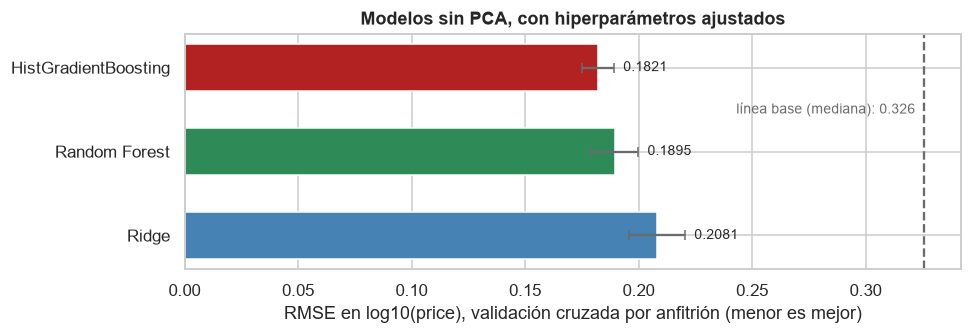

In [12]:
orden = tabla_ajustados.sort_values("rmse", ascending=False).index
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(orden, tabla_ajustados.loc[orden, "rmse"], xerr=tabla_ajustados.loc[orden, "rmse_de"],
        color=[COLOR_MODELO[n] for n in orden], height=0.55, error_kw={"ecolor": GRIS, "capsize": 3})
base_rmse = tabla_base.loc["Línea base (mediana)", "rmse"]
ax.axvline(base_rmse, color=GRIS, ls="--", lw=1.5)
ax.text(base_rmse - 0.004, 1.5, f"línea base (mediana): {base_rmse:.3f}", ha="right", va="center", fontsize=9, color=GRIS)
for i, n in enumerate(orden):
    ax.text(tabla_ajustados.loc[n, "rmse"] + tabla_ajustados.loc[n, "rmse_de"] + 0.004, i,
            f"{tabla_ajustados.loc[n, 'rmse']:.4f}", va="center", fontsize=9)
ax.set_xlabel("RMSE en log10(price), validación cruzada por anfitrión (menor es mejor)")
ax.set_title("Modelos sin PCA, con hiperparámetros ajustados")
ax.set_xlim(0, base_rmse * 1.05)
fig.tight_layout()
guardar(fig, "01_modelos_sin_pca.png")
plt.show()

## 5. Análisis de PCA: ¿es necesario y con cuántas variables?

PCA reemplaza las variables originales por combinaciones lineales no correlacionadas (componentes), ordenadas según cuánta varianza capturan.
Ayuda cuando muchas variables están muy correlacionadas o cuando hay demasiadas para el número de filas. Se revisa primero si este dataset cumple esas condiciones.

### 5.1 Varianza explicada

,componentes
70% de la varianza,28
80% de la varianza,35
90% de la varianza,44
95% de la varianza,51
99% de la varianza,59
Criterio de Kaiser (autovalor > 1),27


Variables de entrada: 67. PC1 explica 10.0%, PC2 5.2%, PC3 5.1%; las 5 primeras 27.9%
Pares de variables con |r| > 0.7: 8 de 2,211; |r| mediano: 0.029


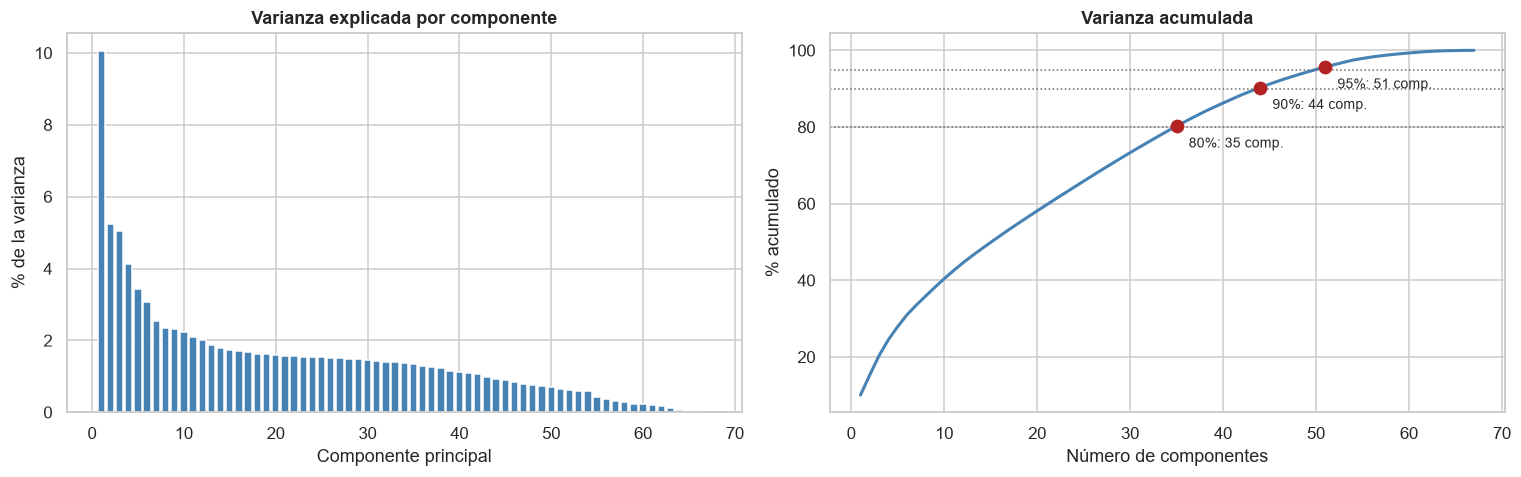

In [13]:
# Se ajusta solo con entrenamiento: PCA completo para ver cuánta varianza captura cada componente
Z_train = crear_prep().fit_transform(X_train)
pca_full = PCA(random_state=SEMILLA).fit(Z_train)
var = pca_full.explained_variance_ratio_
acum = var.cumsum()
p = Z_train.shape[1]

k_umbral = {f"{u}% de la varianza": int(np.searchsorted(acum, u / 100) + 1) for u in [70, 80, 90, 95, 99]}
k_umbral["Criterio de Kaiser (autovalor > 1)"] = int((pca_full.explained_variance_ > 1).sum())
display(pd.Series(k_umbral, name="componentes").to_frame())
print(f"Variables de entrada: {p}. PC1 explica {var[0]:.1%}, PC2 {var[1]:.1%}, PC3 {var[2]:.1%}; las 5 primeras {acum[4]:.1%}")

corr = np.abs(np.corrcoef(Z_train, rowvar=False))
pares = corr[np.triu_indices(p, 1)]
print(f"Pares de variables con |r| > 0.7: {(pares > 0.7).sum()} de {len(pares):,}; |r| mediano: {np.median(pares):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, p + 1), var * 100, color=AZUL)
axes[0].set_title("Varianza explicada por componente")
axes[0].set_xlabel("Componente principal"); axes[0].set_ylabel("% de la varianza")
axes[1].plot(range(1, p + 1), acum * 100, color=AZUL, lw=2)
for u in [80, 90, 95]:
    k = k_umbral[f"{u}% de la varianza"]
    axes[1].axhline(u, color=GRIS, ls=":", lw=1)
    axes[1].plot(k, acum[k - 1] * 100, "o", ms=8, color=ACENTO)
    axes[1].annotate(f"{u}%: {k} comp.", (k, acum[k - 1] * 100), xytext=(8, -14), textcoords="offset points", fontsize=9)
axes[1].set_title("Varianza acumulada")
axes[1].set_xlabel("Número de componentes"); axes[1].set_ylabel("% acumulado")
fig.tight_layout()
guardar(fig, "02_varianza_pca.png")
plt.show()

**Figura 2. Varianza explicada por componente.** La varianza está muy repartida: la primera componente explica solo 10.0% y las cinco primeras, 27.9%.
Para llegar al 80% se necesitan 35 componentes, para el 90% 44 y para el 95% 51; el criterio de Kaiser retiene 27. No hay un "codo" claro donde cortar.

Esto concuerda con la estructura de los datos: solo 8 de 2,211 pares de variables tienen |r| > 0.7, y la correlación absoluta mediana es 0.029.
**Hay muy poca redundancia que PCA pueda comprimir.** Además, 51 de las 67 variables son binarias. Al estandarizarlas, una categoría rara como Milpa Alta
cuenta con la misma varianza que `accommodates`, y PCA reparte varianza en ejes que tienen poco que ver con el precio. Con 18,433 filas y 67 variables tampoco
hay un problema de exceso de dimensiones.

### 5.2 Qué representan las componentes

Las primeras componentes sí tienen lectura: PC1 es equipamiento, PC2 es tamaño del alojamiento (la más correlacionada con el precio, 0.455), PC3 es falta de
historial del anfitrión, y PC5 y PC6 son geografía. Pero cada una mezcla decenas de variables, y explicarle a un anfitrión el efecto de "PC4" es mucho menos claro que hablar de recámaras o de ubicación.

In [14]:
nombres_z = NUMERICAS + ASIMETRICAS + BINARIAS
cargas = pd.DataFrame(pca_full.components_[:6].T, index=nombres_z, columns=[f"PC{i + 1}" for i in range(6)])
Z_pc = pca_full.transform(Z_train)
filas = []
for i, pc in enumerate(cargas.columns):
    top = cargas[pc].abs().sort_values(ascending=False).head(5).index
    filas.append({"componente": pc, "% varianza": round(var[i] * 100, 1),
                  "corr. con log_price": round(np.corrcoef(Z_pc[:, i], y_train)[0, 1], 3),
                  "variables con mayor carga": ", ".join(f"{c} ({cargas.loc[c, pc]:+.2f})" for c in top)})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(filas).set_index("componente"))

,% varianza,corr. con log_price,variables con mayor carga
componente,,,
PC1,10.0000,0.3870,"amenities_count (+0.31), amen_dishes_and_silverware (+0.27), amen_cooking_basics (+0.27), amen_hot_water (+0.26), amen_hangers (+0.25)"
PC2,5.2000,0.4550,"bedrooms (+0.37), accommodates (+0.36), beds (+0.35), bathrooms (+0.30), sin_tasa_aceptacion (+0.26)"
PC3,5.1000,-0.2330,"host_sin_perfil (+0.42), verif_phone (-0.41), sin_tasa_aceptacion (+0.36), host_response_category_Sin historial (+0.34), verif_email (-0.26)"
PC4,4.1000,0.1090,"host_acceptance_rate (+0.29), latitude (+0.28), is_instant_bookable (+0.28), host_response_rate (+0.28), host_response_category_Slow (-0.26)"
PC5,3.4000,0.1560,"latitude (+0.38), property_group_Entire rental unit (+0.28), longitude (-0.24), host_response_rate (-0.24), neighbourhood_cleansed_Coyoacán (-0.24)"
PC6,3.1000,-0.1610,"longitude (+0.52), neighbourhood_cleansed_Cuajimalpa de Morelos (-0.27), neighbourhood_cleansed_Miguel Hidalgo (-0.24), neighbourhood_cleansed_Venustiano Carranza (+0.24), host_listings_count (-0.23)"


### 5.3 Modelo con PCA contra modelo sin PCA, según el número de componentes

Cada combinación se evalúa con la misma validación por anfitrión, y PCA se recalcula dentro de cada partición. Se incluyen los k de los umbrales de varianza
y k = 67, que conserva todas las dimensiones: no reduce nada, solo rota los ejes, y sirve para separar el efecto de rotar del efecto de descartar información.

In [15]:
# Misma validación por anfitrión; PCA se ajusta dentro de cada partición
# La rejilla incluye los k de los umbrales de varianza; k = p no reduce nada, solo rota los ejes
k70, k80, k90, k95, k99 = (k_umbral[f"{u}% de la varianza"] for u in [70, 80, 90, 95, 99])
K_DENSO = sorted({2, 5, 10, 15, 20, k70, k80, k90, k95, k99, p})
K_RF = sorted({5, 10, 20, k80, k95, k99, p})   # Random Forest es mucho más lento: menos puntos
inicio = time.time()
filas = []
for nombre, fabrica in MEJORES.items():
    for k in (K_RF if nombre == "Random Forest" else K_DENSO):
        r = evaluar_cv(con_prep(fabrica(), pca=k))
        filas.append({"modelo": nombre, "k": k, "rmse": r["rmse"].mean(), "rmse_de": r["rmse"].std(ddof=1),
                      "r2": r["r2"].mean(), "mdape": r["mdape"].mean(), "segundos": r["segundos"].mean()})
curva = pd.DataFrame(filas)
print(f"Curva calculada en {(time.time() - inicio) / 60:.1f} minutos")

# Mejor k que de verdad reduce (k < p), y k mínimo cuyo RMSE no se distingue del mismo modelo
# sin PCA según la regla de un error estándar
filas = []
K_ELEGIDO = {}
for nombre in MEJORES:
    c = curva[curva["modelo"] == nombre].sort_values("k")
    s = tabla_ajustados.loc[nombre]
    tolerancia = s["rmse"] + s["rmse_de"] / np.sqrt(5)
    reducen = c[c["k"] < p]
    equivalentes = reducen[reducen["rmse"] <= tolerancia]
    mejor = reducen.loc[reducen["rmse"].idxmin()]
    K_ELEGIDO[nombre] = int(mejor["k"])
    filas.append({"modelo": nombre, "RMSE sin PCA": s["rmse"], "mejor k < p": int(mejor["k"]), "RMSE con esa k": mejor["rmse"],
                  "cambio %": (mejor["rmse"] / s["rmse"] - 1) * 100,
                  f"RMSE k={p} (solo rota)": c.loc[c["k"] == p, "rmse"].iloc[0],
                  "tolerancia (1 EE)": tolerancia,
                  "k mínimo equivalente": int(equivalentes["k"].min()) if len(equivalentes) else "ninguno",
                  "s sin PCA": s["segundos"], "s con esa k": mejor["segundos"]})
tabla_pca = pd.DataFrame(filas).set_index("modelo")
display(tabla_pca.round(4))
display(curva.pivot(index="k", columns="modelo", values="rmse").round(4))

Curva calculada en 3.3 minutos


,RMSE sin PCA,mejor k < p,RMSE con esa k,cambio %,RMSE k=67 (solo rota),tolerancia (1 EE),k mínimo equivalente,s sin PCA,s con esa k
modelo,,,,,,,,,
Ridge,0.2081,59,0.2125,2.0931,0.2081,0.2137,59,0.0902,0.1060
Random Forest,0.1895,59,0.2111,11.3553,0.2067,0.1942,ninguno,1.2809,5.6056
HistGradientBoosting,0.1821,59,0.2065,13.4252,0.1959,0.1853,ninguno,1.4471,1.5993


modelo,HistGradientBoosting,Random Forest,Ridge
k,,,
2,0.2533,NaN,0.2618
5,0.2335,0.2351,0.2422
10,0.2211,0.2203,0.2352
15,0.2146,NaN,0.2255
20,0.2135,0.2139,0.2238
28,0.2131,NaN,0.2234
35,0.2130,0.2144,0.2216
44,0.2104,NaN,0.2180
51,0.2085,0.2133,0.2167


**Lectura de la tabla.**

| Componentes (k) | Ridge | Random Forest | HistGradientBoosting |
|---|---|---|---|
| 35 (80% de varianza) | +6.5% | +13.1% | +17.0% |
| 51 (95% de varianza) | +4.1% | +12.6% | +14.5% |
| 59 (99% de varianza) | +2.1% | +11.4% | +13.4% |
| 67 (solo rotación) | 0.0% | +9.0% | +7.6% |

*Cambio del RMSE respecto al mismo modelo sin PCA, calculado de las tablas de arriba.*

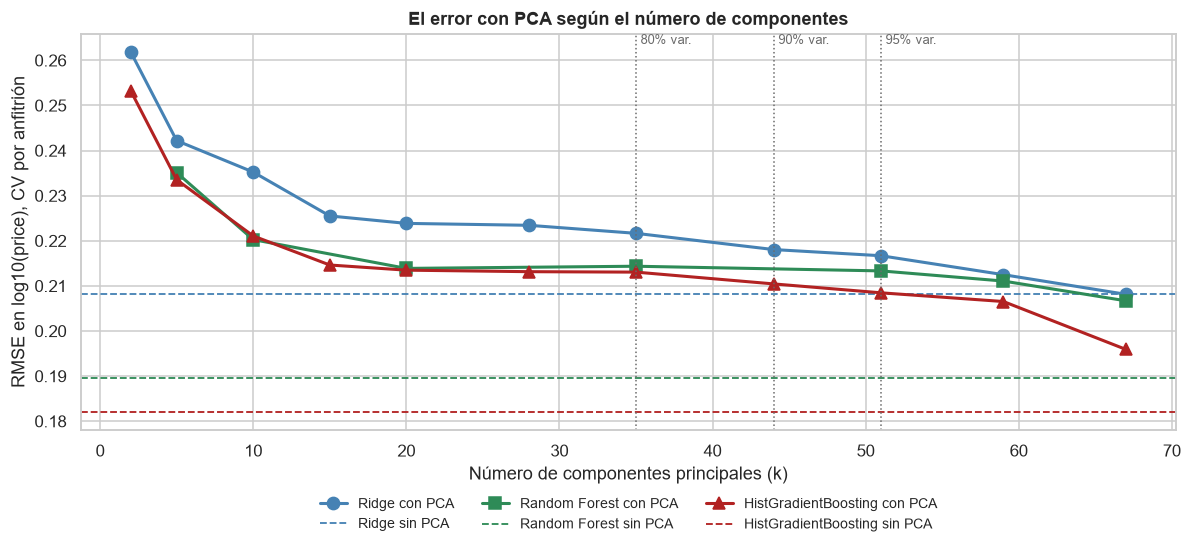

In [16]:
fig, ax = plt.subplots(figsize=(11, 5.2))
MARCADOR = {"Ridge": "o", "Random Forest": "s", "HistGradientBoosting": "^"}   # el color no identifica por sí solo
for nombre, color in COLOR_MODELO.items():
    c = curva[curva["modelo"] == nombre].sort_values("k")
    ax.plot(c["k"], c["rmse"], marker=MARCADOR[nombre], ms=8, lw=2, color=color, label=f"{nombre} con PCA")
    ax.axhline(tabla_ajustados.loc[nombre, "rmse"], color=color, ls="--", lw=1.2, label=f"{nombre} sin PCA")
tope = ax.get_ylim()[1]
for u in [80, 90, 95]:
    k = k_umbral[f"{u}% de la varianza"]
    ax.axvline(k, color=GRIS, ls=":", lw=1)
    ax.text(k + 0.3, tope, f"{u}% var.", fontsize=8.5, color=GRIS, va="top")
ax.set_xlabel("Número de componentes principales (k)")
ax.set_ylabel("RMSE en log10(price), CV por anfitrión")
ax.set_title("El error con PCA según el número de componentes")
ax.legend(fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False)
fig.tight_layout()
guardar(fig, "03_curva_pca.png")
plt.show()

**Figura 3. El error con PCA según el número de componentes.** Las líneas sólidas son los modelos con PCA y las punteadas horizontales, el mismo modelo sin PCA.

- **Ninguna k mejora al modelo sin PCA.** El error baja a medida que se agregan componentes, sin un punto donde se estabilice antes de usarlas todas.
- **Las componentes de poca varianza también predicen.** Pasar de 35 a 59 componentes reduce el error aunque esas componentes aporten poca varianza.
  PCA elige por varianza de las variables de entrada, sin mirar el precio, y aquí varianza e información sobre el precio no coinciden.
- **Ridge con k = 67 da el mismo resultado que sin PCA,** como se espera en un modelo lineal: rotar no cambia lo que puede representar. Confirma que la comparación está bien montada.
- **Los árboles empeoran incluso sin descartar nada** (+7.6% y +9.0% con k = 67). Un árbol corta en una variable a la vez ("¿tiene más de 3 recámaras?"), y
  al rotar los ejes esos cortes dejan de corresponder a variables con significado.
- **¿Con cuántas componentes se iguala al modelo sin PCA?** Aplicando la regla de un error estándar, solo Ridge con k = 59 queda dentro de la tolerancia (0.2125 contra 0.2137).
  Random Forest y HistGradientBoosting no la alcanzan con ninguna k. Y aun así, Ridge con k = 59 (0.2125) queda lejos de HistGradientBoosting sin PCA (0.1821).
- **PCA tampoco ahorra tiempo.** HistGradientBoosting tarda lo mismo con o sin PCA, y Random Forest pasa de cerca de 1.4 a 6.4 segundos por ajuste.

### 5.4 Alternativa: PCA solo en el bloque de capacidad

El único grupo con colinealidad fuerte es el de capacidad, y el EDA sugirió combinarlo en un índice de tamaño. Se prueba reemplazar `accommodates`, `bedrooms`, `beds` y `bathrooms`
por una sola componente.

In [17]:
# Alternativa: PCA solo sobre el bloque de capacidad, el único con colinealidad fuerte según el EDA
CAPACIDAD = ["accommodates", "bedrooms", "beds", "bathrooms"]
OTRAS = [c for c in NUMERICAS if c not in CAPACIDAD]


def prep_bloque():
    return ColumnTransformer([
        ("capacidad", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler()),
                                ("pca", PCA(n_components=1, random_state=SEMILLA))]), CAPACIDAD),
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), OTRAS),
        ("asim", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                           ("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), ASIMETRICAS),
        ("bin", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")), ("escalar", StandardScaler())]), BINARIAS),
    ])


bloque = Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler()), ("p", PCA(random_state=SEMILLA))]).fit(X_train[CAPACIDAD])
print("Varianza del bloque de capacidad por componente:", np.round(bloque["p"].explained_variance_ratio_, 3))
print("Cargas de la primera componente:", dict(zip(CAPACIDAD, np.round(bloque["p"].components_[0], 3))))

filas = []
for nombre, fabrica in MEJORES.items():
    r = evaluar_cv(Pipeline([("prep", prep_bloque()), ("modelo", fabrica())]))
    filas.append({"modelo": nombre, "RMSE sin PCA": tabla_ajustados.loc[nombre, "rmse"], "RMSE con índice de capacidad": r["rmse"].mean(),
                  "cambio %": (r["rmse"].mean() / tabla_ajustados.loc[nombre, "rmse"] - 1) * 100})
tabla_bloque = pd.DataFrame(filas).set_index("modelo")
tabla_bloque.round(4)

Varianza del bloque de capacidad por componente: [0.771 0.139 0.052 0.038]
Cargas de la primera componente: {'accommodates': np.float64(0.522), 'bedrooms': np.float64(0.526), 'beds': np.float64(0.517), 'bathrooms': np.float64(0.429)}


,RMSE sin PCA,RMSE con índice de capacidad,cambio %
modelo,,,
Ridge,0.2081,0.2096,0.7112
Random Forest,0.1895,0.1963,3.5710
HistGradientBoosting,0.1821,0.1886,3.5674


La primera componente resume bien el bloque (77.1% de su varianza, con cargas parecidas de las cuatro variables), pero el error **sube** en los tres modelos: +0.7% en Ridge y
+3.6% en los de árboles. Las diferencias entre las cuatro variables también informan sobre el precio, así que el índice no se justifica.

### 5.5 Comparación pareada y reajuste

Se comparan las mismas 5 particiones con y sin PCA, usando la k de menor error que sí reduce dimensiones (k = 59).

In [18]:
# Comparación pareada por partición: mismas 5 particiones, con y sin PCA (k de menor error)
filas = []
for nombre, fabrica in MEJORES.items():
    con = evaluar_cv(con_prep(fabrica(), pca=K_ELEGIDO[nombre]))["rmse"].to_numpy()
    sin = part_sin_pca[nombre]["rmse"].to_numpy()
    filas.append({"modelo": nombre, "k": K_ELEGIDO[nombre], "diferencia media (PCA - sin PCA)": (con - sin).mean(),
                  "particiones en que PCA gana": int((con < sin).sum()),
                  "diferencia mín.": (con - sin).min(), "diferencia máx.": (con - sin).max()})
tabla_pareada = pd.DataFrame(filas).set_index("modelo")
tabla_pareada.round(4)

,k,diferencia media (PCA - sin PCA),particiones en que PCA gana,diferencia mín.,diferencia máx.
modelo,,,,,
Ridge,59,0.0044,0,0.0023,0.0077
Random Forest,59,0.0215,0,0.0165,0.0260
HistGradientBoosting,59,0.0244,0,0.0194,0.0279


**PCA no gana en ninguna de las 5 particiones, en ninguno de los tres modelos.** El resultado no depende de cómo cayeron los datos.

Queda una objeción posible: los hiperparámetros se ajustaron sin PCA, y eso podría perjudicarlo. Para descartarla, HistGradientBoosting con k = 59 recibe su propia búsqueda, con el mismo espacio y el mismo número de combinaciones.

In [19]:
# Comparación justa: el modelo final con PCA también recibe su propia búsqueda de hiperparámetros
k_final = K_ELEGIDO["HistGradientBoosting"]
busqueda_pca = RandomizedSearchCV(con_prep(HistGradientBoostingRegressor(random_state=SEMILLA), pca=k_final), ESPACIO_HGB,
                                  n_iter=15, cv=CV, scoring="neg_root_mean_squared_error",
                                  random_state=SEMILLA, n_jobs=1).fit(X_train, y_train, groups=g_train)
FINAL = tabla_ajustados["rmse"].idxmin()
print(f"Mejores hiperparámetros con PCA (k={k_final}): {sin_prefijo(busqueda_pca.best_params_)}")
print(f"RMSE CV -> HistGradientBoosting sin PCA: {tabla_ajustados.loc['HistGradientBoosting', 'rmse']:.4f} | "
      f"con PCA reajustado: {-busqueda_pca.best_score_:.4f} | "
      f"cambio: {(-busqueda_pca.best_score_ / tabla_ajustados.loc['HistGradientBoosting', 'rmse'] - 1) * 100:+.1f}%")

Mejores hiperparámetros con PCA (k=59): {'min_samples_leaf': 40, 'max_leaf_nodes': 15, 'max_iter': 500, 'max_features': 0.5, 'learning_rate': 0.05, 'l2_regularization': 5.0}
RMSE CV -> HistGradientBoosting sin PCA: 0.1821 | con PCA reajustado: 0.2061 | cambio: +13.2%


Con su propio ajuste, el modelo con PCA apenas mejora (RMSE de 0.2065 a 0.2061) y sigue 13.2% por encima del modelo sin PCA. La desventaja no se debía a los hiperparámetros.

## 6. Evaluación final en el conjunto de prueba

Esta es la primera vez que se usan los 4,600 anuncios de prueba, de 2,021 anfitriones que ningún modelo ha visto. Las decisiones ya están tomadas con validación cruzada, así que estas métricas no están contaminadas por la selección.

**Métricas utilizadas:**

| Métrica | Qué mide | Por qué se reporta |
|---|---|---|
| **RMSE log10** | Error cuadrático en la escala en que se entrena | Es el criterio de selección y penaliza los errores grandes |
| **MAE log10** | Error absoluto en la misma escala | Menos sensible a extremos |
| **R² log10** | Proporción de la variación explicada | Permite comparar contra predecir siempre el promedio |
| **RMSE \$** | Error cuadrático en pesos | Se lee en la unidad del negocio, pero lo dominan los anuncios muy caros |
| **MAE \$ y MdAE \$** | Error absoluto medio y mediano en pesos | El mediano describe el error de un anuncio típico |
| **R² \$** | Variación explicada en pesos | Se reporta por transparencia: la dominan los precios altos |
| **MAPE % y MdAPE %** | Error porcentual medio y mediano | Comparables entre anuncios baratos y caros |
| **Dentro de ±20% y ±30%** | % de anuncios con error menor a ese margen | La lectura más directa de "qué tan seguido acierta" |

Al volver a pesos con 10^predicción se estima aproximadamente la mediana del precio, no la media. Por eso el modelo tiende a quedar por debajo en la cola alta, y las métricas en pesos deben leerse con esa advertencia.

In [20]:
def metricas(y_real, y_pred):
    """Métricas en escala log10 y de vuelta en pesos. 10^pred estima la mediana condicional del precio."""
    real, pred = 10 ** np.asarray(y_real), 10 ** np.asarray(y_pred)
    ratio = np.abs(pred - real) / real
    return {"RMSE log10": np.sqrt(mean_squared_error(y_real, y_pred)),
            "MAE log10": mean_absolute_error(y_real, y_pred),
            "R² log10": r2_score(y_real, y_pred),
            "RMSE $": np.sqrt(mean_squared_error(real, pred)),
            "MAE $": mean_absolute_error(real, pred),
            "MdAE $": np.median(np.abs(pred - real)),
            "R² $": r2_score(real, pred),
            "MAPE %": ratio.mean() * 100,
            "MdAPE %": np.median(ratio) * 100,
            "dentro de ±20%": (ratio <= 0.2).mean() * 100,
            "dentro de ±30%": (ratio <= 0.3).mean() * 100}


entrenados, predicciones = {}, {}


def ajustar(etiqueta, pipe):
    inicio = time.time()
    pipe.fit(X_train, y_train)
    entrenados[etiqueta] = pipe
    predicciones[etiqueta] = pipe.predict(X_test)
    return time.time() - inicio


tiempos = {"Línea base (mediana)": ajustar("Línea base (mediana)", con_prep(DummyRegressor(strategy="median")))}
for nombre, fabrica in MEJORES.items():
    tiempos[f"{nombre} sin PCA"] = ajustar(f"{nombre} sin PCA", con_prep(fabrica()))
    etq = f"{nombre} con PCA (k={K_ELEGIDO[nombre]})"
    tiempos[etq] = ajustar(etq, con_prep(fabrica(), pca=K_ELEGIDO[nombre]))
    if K_ELEGIDO[nombre] != k95:
        etq95 = f"{nombre} con PCA (k={k95}, 95% var.)"
        tiempos[etq95] = ajustar(etq95, con_prep(fabrica(), pca=k95))
etq_pca_aj = f"HistGradientBoosting con PCA reajustado (k={K_ELEGIDO['HistGradientBoosting']})"
tiempos[etq_pca_aj] = ajustar(etq_pca_aj, con_prep(HistGradientBoostingRegressor(random_state=SEMILLA, **sin_prefijo(busqueda_pca.best_params_)),
                                                   pca=K_ELEGIDO["HistGradientBoosting"]))

evaluacion = pd.DataFrame({n: metricas(y_test, p_) for n, p_ in predicciones.items()}).T
evaluacion["entrenar (s)"] = pd.Series(tiempos)
evaluacion.round(3)

,RMSE log10,MAE log10,R² log10,RMSE $,MAE $,MdAE $,R² $,MAPE %,MdAPE %,dentro de ±20%,dentro de ±30%,entrenar (s)
Línea base (mediana),0.3340,0.2610,-0.0060,"1,695.1560",795.2750,487.0000,-0.0400,74.4110,47.3300,23.7390,34.4780,0.1110
Ridge sin PCA,0.2050,0.1550,0.6190,"1,198.4800",514.4040,253.9880,0.4800,38.7520,27.8950,38.2390,52.8700,0.1160
Ridge con PCA (k=59),0.2110,0.1600,0.5990,"1,214.9870",526.7460,263.4220,0.4660,40.2930,28.3870,38.0650,52.0430,0.1270
"Ridge con PCA (k=51, 95% var.)",0.2180,0.1650,0.5690,"1,255.1980",545.5290,278.9210,0.4300,42.5580,29.3650,36.6520,51.0650,0.1190
Random Forest sin PCA,0.1890,0.1390,0.6780,"1,164.5080",471.3610,219.5780,0.5090,34.6740,24.7100,41.7610,58.4130,1.8670
Random Forest con PCA (k=59),0.2110,0.1590,0.5980,"1,266.9790",523.4570,253.1720,0.4190,40.3200,28.6220,36.9130,51.8910,7.0570
"Random Forest con PCA (k=51, 95% var.)",0.2130,0.1600,0.5920,"1,267.8360",527.8320,258.2030,0.4180,40.7610,28.8240,36.1960,51.3480,5.7160
HistGradientBoosting sin PCA,0.1790,0.1310,0.7110,"1,111.5140",450.3690,206.3140,0.5530,32.3390,22.6810,45.4570,61.3700,1.8460
HistGradientBoosting con PCA (k=59),0.2000,0.1500,0.6380,"1,185.7640",500.9830,240.1000,0.4910,37.5130,26.3720,39.2830,54.9130,1.5760
"HistGradientBoosting con PCA (k=51, 95% var.)",0.2050,0.1540,0.6210,"1,206.4990",514.0000,246.3890,0.4730,38.5360,27.2270,39.2170,54.1960,1.3060


**Resultados en prueba.** Sin PCA, HistGradientBoosting es el mejor en todas las métricas, igual que en validación. Frente a la línea base reduce el RMSE log10 en 46% (0.334 a 0.179),
el MAE en pesos en 43% (\$795 a \$450) y el error mediano en pesos en 58% (\$487 a \$206).

Falta comprobar si la diferencia con PCA podría deberse al azar de la muestra. Se calcula un intervalo de confianza con 2,000 remuestreos **de anfitriones**, porque los anuncios de un mismo anfitrión no son independientes.

In [21]:
# Elección del modelo final por CV (no por prueba) y su contraparte con PCA
FINAL = tabla_ajustados["rmse"].idxmin()
assert FINAL == "HistGradientBoosting", "La narrativa y el reajuste con PCA suponen este modelo final"
etq_sin, etq_con = f"{FINAL} sin PCA", etq_pca_aj
print(f"Modelo final elegido por validación cruzada: {etq_sin}. Se compara contra: {etq_con}")

# Intervalo de confianza de la diferencia en prueba, remuestreando anfitriones y no filas
rng = np.random.default_rng(SEMILLA)
error_sin = (y_test.to_numpy() - predicciones[etq_sin]) ** 2
error_con = (y_test.to_numpy() - predicciones[etq_con]) ** 2
unicos, codigos = np.unique(grupos_total.iloc[test].to_numpy(), return_inverse=True)
sum_sin, sum_con, n_host = np.bincount(codigos, error_sin), np.bincount(codigos, error_con), np.bincount(codigos)
difs = []
for _ in range(2000):
    m = rng.integers(0, len(unicos), len(unicos))
    difs.append(np.sqrt(sum_con[m].sum() / n_host[m].sum()) - np.sqrt(sum_sin[m].sum() / n_host[m].sum()))
ic = np.percentile(difs, [2.5, 97.5])
print(f"RMSE log10 en prueba -> sin PCA: {np.sqrt(error_sin.mean()):.4f} | con PCA: {np.sqrt(error_con.mean()):.4f}")
print(f"Diferencia (con PCA - sin PCA): {np.sqrt(error_con.mean()) - np.sqrt(error_sin.mean()):+.4f} | IC 95% por anfitrión: [{ic[0]:+.4f}, {ic[1]:+.4f}]")

Modelo final elegido por validación cruzada: HistGradientBoosting sin PCA. Se compara contra: HistGradientBoosting con PCA reajustado (k=59)
RMSE log10 en prueba -> sin PCA: 0.1790 | con PCA: 0.2012
Diferencia (con PCA - sin PCA): +0.0222 | IC 95% por anfitrión: [+0.0154, +0.0293]


**La diferencia es real.** El RMSE sube de 0.1790 a 0.2012 con PCA (+12.4%), y el intervalo de confianza de 95% de esa diferencia, [+0.0154, +0.0293], no incluye el cero.

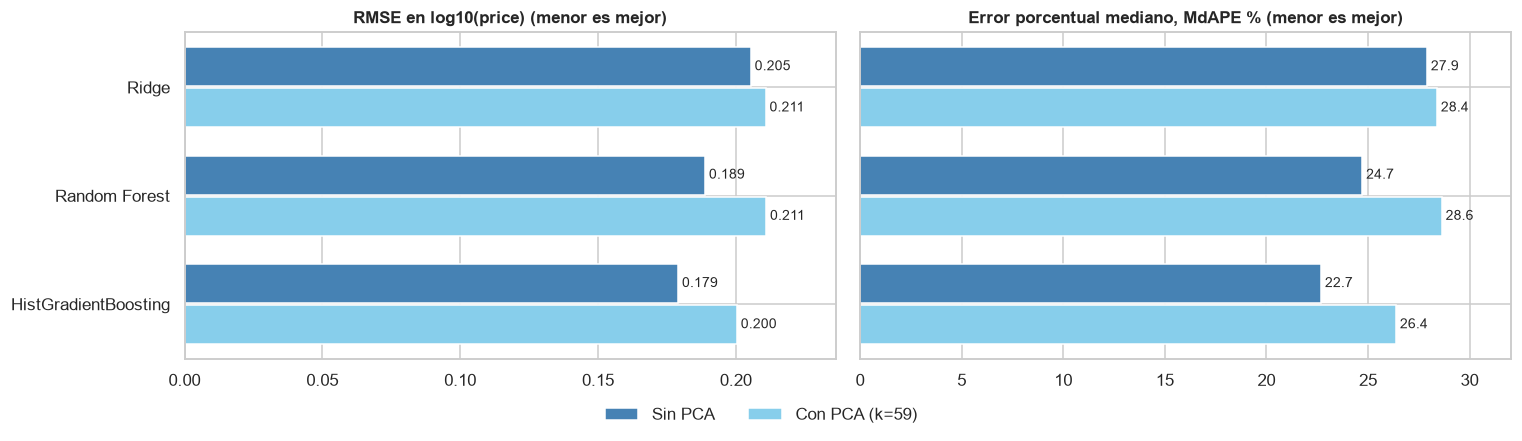

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
modelos = list(MEJORES)
posiciones = np.arange(len(modelos))
for ax, metrica, titulo, fmt in zip(axes, ["RMSE log10", "MdAPE %"],
                                    ["RMSE en log10(price) (menor es mejor)", "Error porcentual mediano, MdAPE % (menor es mejor)"],
                                    [" {:.3f}", " {:.1f}"]):
    sin = [evaluacion.loc[f"{m} sin PCA", metrica] for m in modelos]
    con = [evaluacion.loc[f"{m} con PCA (k={K_ELEGIDO[m]})", metrica] for m in modelos]
    ax.barh(posiciones - 0.19, sin, height=0.36, color=AZUL, label="Sin PCA")
    ax.barh(posiciones + 0.19, con, height=0.36, color=AZUL_CLARO, label=f"Con PCA (k={K_ELEGIDO[FINAL]})")
    for y_, v in list(zip(posiciones - 0.19, sin)) + list(zip(posiciones + 0.19, con)):
        ax.text(v, y_, fmt.format(v), va="center", fontsize=9)
    ax.set_title(titulo, fontsize=11)
    ax.margins(x=0.12)
axes[0].set_yticks(posiciones, modelos)
axes[0].invert_yaxis()
manijas, etiquetas = axes[0].get_legend_handles_labels()
fig.legend(manijas, etiquetas, frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.07))
fig.tight_layout()
guardar(fig, "04_evaluacion_prueba.png")
plt.show()

**Figura 4. Evaluación en prueba con y sin PCA.** PCA con k = 59 empeora los tres modelos. El efecto es pequeño en Ridge (0.205 a 0.211) y grande en los de árboles, que son justamente los mejores.
En el modelo final, el error porcentual mediano sube de 22.7% a 26.4%. Con su propio reajuste queda en 26.7%, sin mejora.

### 6.1 Sensibilidad a las decisiones tomadas

Se revisa cuánto dependen los resultados de excluir los precios extremos y de usar el historial del anuncio.

In [23]:
modelo_final = entrenados[etq_sin]
COLS_S = ["RMSE log10", "R² log10", "RMSE $", "MAE $", "MdAPE %", "dentro de ±20%"]
filas = {"Prueba limpia": metricas(y_test, modelo_final.predict(X_test)),
         "Prueba con precios extremos": metricas(y_test_total, modelo_final.predict(X_test_total))}

# ¿Y si se entrena sin descartar extremos? Se evalúa sobre la misma prueba limpia
X_tr_ext, y_tr_ext = df_modelo.iloc[idx_train][VARIABLES].astype(float), y_total.iloc[idx_train]
con_ext = con_prep(MEJORES[FINAL]()).fit(X_tr_ext, y_tr_ext)
filas["Entrenado con extremos, prueba limpia"] = metricas(y_test, con_ext.predict(X_test))

# Anuncio nuevo: sin variables que dependen de su historial en la plataforma
HISTORIAL = ["number_of_reviews", "reviews_per_month", "review_scores_rating", "sin_resenas", "availability_365"]
ASIM_N = [c for c in ASIMETRICAS if c not in HISTORIAL]
NUM_N = [c for c in NUMERICAS if c not in HISTORIAL]
BIN_N = [c for c in BINARIAS if c not in HISTORIAL]
prep_n = ColumnTransformer([
    ("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), NUM_N),
    ("asim", Pipeline([("l", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                       ("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), ASIM_N),
    ("bin", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("s", StandardScaler())]), BIN_N)])
nuevo = Pipeline([("prep", prep_n), ("modelo", MEJORES[FINAL]())]).fit(X_train, y_train)
filas["Sin historial del anuncio, prueba limpia"] = metricas(y_test, nuevo.predict(X_test))

print(f"Anuncios extremos en prueba: {len(test_total) - len(test)}")
pd.DataFrame(filas).T[COLS_S].round(3)

Anuncios extremos en prueba: 1


,RMSE log10,R² log10,RMSE $,MAE $,MdAPE %,dentro de ±20%
Prueba limpia,0.1790,0.7110,"1,111.5140",450.3690,22.6810,45.4570
Prueba con precios extremos,0.1800,0.7080,"1,139.6640",453.9900,22.6850,45.4470
"Entrenado con extremos, prueba limpia",0.1800,0.7090,"1,102.2870",454.9490,23.0680,44.3910
"Sin historial del anuncio, prueba limpia",0.1910,0.6690,"1,147.9350",481.7530,24.4850,42.0650


- **Precios extremos en prueba:** al incluirlos, el RMSE en pesos sube de \$1,112 a \$1,140. Pero en prueba solo cayó **1** de los 24 anuncios extremos, así que esta comprobación dice poco
  sobre cómo le iría al modelo con muchos de ellos.
- **Entrenar con extremos:** el resultado casi no cambia (error mediano de 23.1% contra 22.7%). La exclusión es una decisión de calidad del dato; no es lo que explica el desempeño.
- **Anuncio nuevo, sin reseñas ni disponibilidad:** el modelo conserva buena parte de su capacidad (R² = 0.669 y error mediano de 24.5%). Esta es la variante que corresponde a sugerir precio a un anuncio
  que aún no tiene historial. Sí sigue usando datos del anfitrión, que un anfitrión primerizo tampoco tendría completos.

### 6.2 Precisión

La **precisión (precision)** es una métrica de clasificación, y este es un modelo de regresión, así que no aplica de forma directa. Sus equivalentes son el error porcentual y el porcentaje de anuncios dentro de ±20% y ±30%.
Para poder reportarla, el precio predicho se convierte en tres gamas de igual tamaño según el entrenamiento: económico, medio y alto.

Cortes de gama: Económico < $777 | Medio hasta $1,393 | Alto por encima
Accuracy sin PCA: 0.721 | con PCA: 0.689 | al azar: cerca de 0.333
              precision    recall  f1-score   support

   Económico      0.843     0.773     0.807      1698
       Medio      0.586     0.664     0.623      1510
        Alto      0.752     0.719     0.735      1392

    accuracy                          0.721      4600
   macro avg      0.727     0.719     0.721      4600
weighted avg      0.731     0.721     0.725      4600



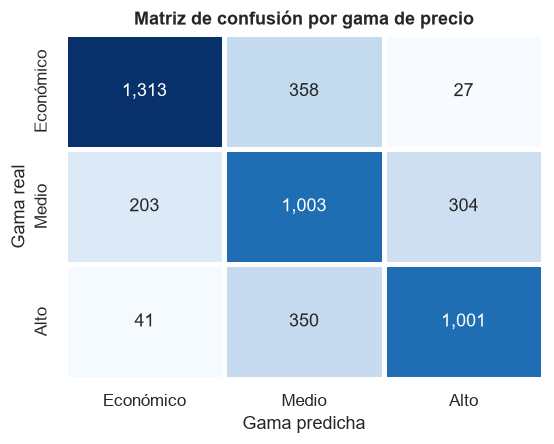

In [24]:
# "Precisión" es una métrica de clasificación. El precio estimado se convierte en tres gamas,
# con cortes calculados en entrenamiento, para medir accuracy, precision y recall.
cortes = 10 ** y_train.quantile([1 / 3, 2 / 3]).to_numpy()
ETIQUETAS = ["Económico", "Medio", "Alto"]


def banda(v):
    return np.digitize(10 ** np.asarray(v), cortes)


real_b, pred_b = banda(y_test), banda(predicciones[etq_sin])
print(f"Cortes de gama: Económico < ${cortes[0]:,.0f} | Medio hasta ${cortes[1]:,.0f} | Alto por encima")
print(f"Accuracy sin PCA: {accuracy_score(real_b, pred_b):.3f} | con PCA: {accuracy_score(real_b, banda(predicciones[etq_con])):.3f} | al azar: cerca de 0.333")
print(classification_report(real_b, pred_b, target_names=ETIQUETAS, digits=3))

matriz = confusion_matrix(real_b, pred_b)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
sns.heatmap(matriz, annot=True, fmt=",d", cmap="Blues", cbar=False, xticklabels=ETIQUETAS, yticklabels=ETIQUETAS, ax=ax, linewidths=2, linecolor="white")
ax.set_xlabel("Gama predicha"); ax.set_ylabel("Gama real")
ax.set_title("Matriz de confusión por gama de precio")
fig.tight_layout()
guardar(fig, "05_matriz_confusion.png")
plt.show()

**Figura 5. Matriz de confusión por gama.** El modelo acierta la gama en el **72.1%** de los anuncios, frente a cerca de 33.3% al azar (68.9% con PCA), con **precisión promedio de 72.7%** y recall de 71.9%.

- **Económico:** precisión de 84.3%. Cuando el modelo dice "económico", casi siempre acierta.
- **Alto:** precisión de 75.2%.
- **Medio:** precisión de 58.6%. Es la gama más difícil porque limita con las otras dos: un error pequeño de precio basta para cambiar de gama cerca de los cortes (\$777 y \$1,393).

## 7. Diagnóstico del modelo final

### 7.1 Predicción y residuos

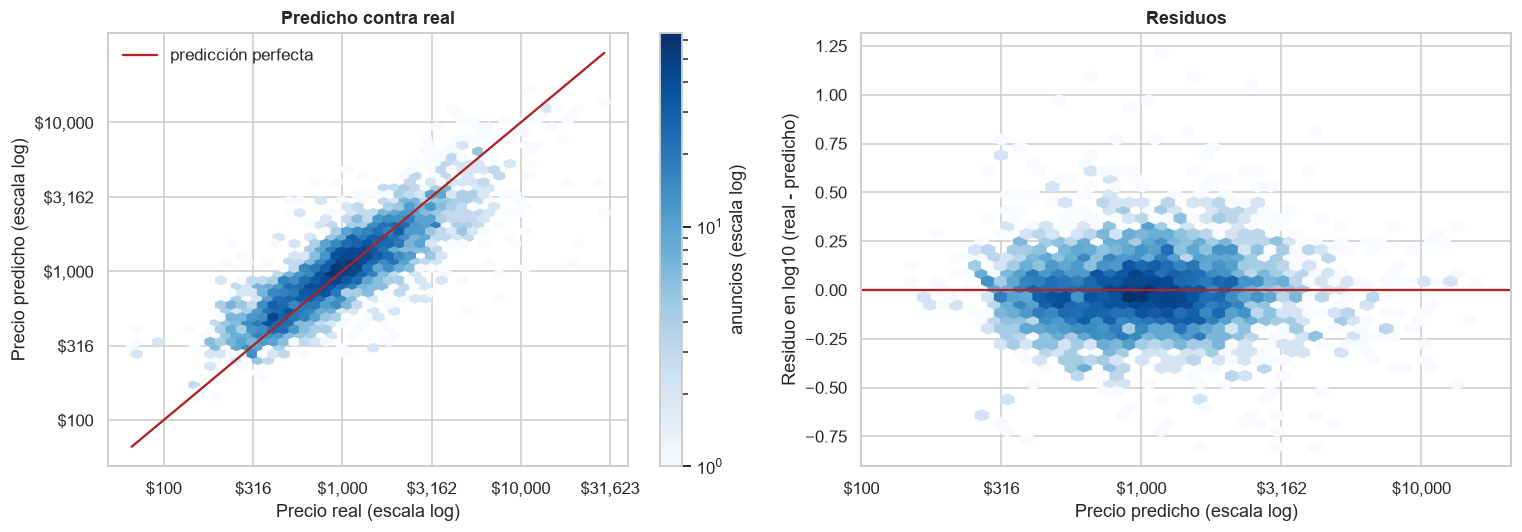

Residuo medio: -0.0098 log10 | asimetría: 0.52


In [25]:
pred = predicciones[etq_sin]
residuo = y_test.to_numpy() - pred
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
h = axes[0].hexbin(y_test, pred, gridsize=45, cmap="Blues", mincnt=1, bins="log")
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, color=ACENTO, lw=1.5, label="predicción perfecta")
ticks = [2, 2.5, 3, 3.5, 4, 4.5]
axes[0].set_xticks(ticks, [f"${10 ** t:,.0f}" for t in ticks]); axes[0].set_yticks(ticks[:-1], [f"${10 ** t:,.0f}" for t in ticks[:-1]])
axes[0].set_xlabel("Precio real (escala log)"); axes[0].set_ylabel("Precio predicho (escala log)")
axes[0].set_title("Predicho contra real"); axes[0].legend(frameon=False, loc="upper left")
fig.colorbar(h, ax=axes[0], label="anuncios (escala log)")
axes[1].hexbin(pred, residuo, gridsize=45, cmap="Blues", mincnt=1, bins="log")
axes[1].axhline(0, color=ACENTO, lw=1.5)
axes[1].set_xticks(ticks[:-1], [f"${10 ** t:,.0f}" for t in ticks[:-1]])
axes[1].set_xlabel("Precio predicho (escala log)"); axes[1].set_ylabel("Residuo en log10 (real - predicho)")
axes[1].set_title("Residuos")
fig.tight_layout()
guardar(fig, "06_prediccion_residuos.png")
plt.show()
print(f"Residuo medio: {residuo.mean():+.4f} log10 | asimetría: {pd.Series(residuo).skew():.2f}")

**Figura 6. Predicho contra real y residuos.** La nube sigue la diagonal, con el residuo medio prácticamente en 0 (−0.0098 en log10). Un RMSE de 0.179 en log10 equivale a un factor típico de error
cercano a 1.5 veces (10^0.179 ≈ 1.51) en cualquier dirección. También se aprecia cierto aplanamiento: la nube queda más horizontal que la diagonal en los extremos, lo que se cuantifica a continuación.

### 7.2 Error por segmento

,anuncios,MdAPE,sesgo_log
rango,,,
<$300,218,63.1860,-0.2340
$300-600,996,23.8380,-0.0890
"$600-1,000",1167,19.1530,-0.0420
"$1,000-2,000",1466,18.9410,0.0240
"$2,000-5,000",626,29.7050,0.1170
"$5,000-10,000",98,43.2230,0.2630
">$10,000",29,43.8530,0.3470


,anuncios,MdAPE
Entire home/apt,3050,21.8000
Private room,1472,24.0000
Shared room,71,32.8000
Hotel room,7,25.4000


,anuncios,MdAPE
Cuauhtémoc,2119,22.8000
Miguel Hidalgo,759,24.5000
Benito Juárez,588,19.3000
Coyoacán,253,23.0000
Venustiano Carranza,147,23.0000
Álvaro Obregón,139,25.8000


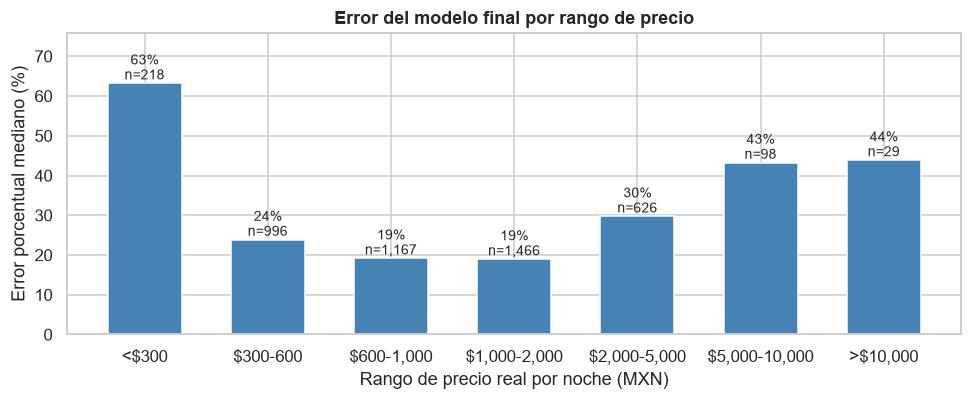

In [26]:
base_seg = df_modelo.iloc[test].copy()
base_seg["pred"] = 10 ** pred
base_seg["err_pct"] = np.abs(base_seg["pred"] - base_seg["price"]) / base_seg["price"] * 100
base_seg["err_log"] = residuo
base_seg["rango"] = pd.cut(base_seg["price"], [0, 300, 600, 1000, 2000, 5000, 10000, np.inf],
                           labels=["<$300", "$300-600", "$600-1,000", "$1,000-2,000", "$2,000-5,000", "$5,000-10,000", ">$10,000"])
por_rango = base_seg.groupby("rango", observed=True).agg(anuncios=("price", "size"), MdAPE=("err_pct", "median"), sesgo_log=("err_log", "mean"))
display(por_rango.round(3))


def desde_dummy(prefijo):
    cols = [c for c in df_modelo.columns if c.startswith(prefijo)]
    return base_seg[cols].idxmax(axis=1).str.removeprefix(prefijo)


por_tipo = base_seg.groupby(desde_dummy("room_type_")).agg(anuncios=("price", "size"), MdAPE=("err_pct", "median")).sort_values("anuncios", ascending=False)
por_alc = base_seg.groupby(desde_dummy("neighbourhood_cleansed_")).agg(anuncios=("price", "size"), MdAPE=("err_pct", "median")).sort_values("anuncios", ascending=False)
display(por_tipo.round(1)); display(por_alc.head(6).round(1))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(por_rango.index.astype(str), por_rango["MdAPE"], color=AZUL, width=0.6)
for i, (v, n) in enumerate(zip(por_rango["MdAPE"], por_rango["anuncios"])):
    ax.text(i, v + 1, f"{v:.0f}%\nn={n:,}", ha="center", fontsize=9)
ax.set_ylabel("Error porcentual mediano (%)"); ax.set_xlabel("Rango de precio real por noche (MXN)")
ax.set_title("Error del modelo final por rango de precio"); ax.margins(y=0.2)
fig.tight_layout()
guardar(fig, "07_error_por_rango.png")
plt.show()

**Figura 7. Error por rango de precio.** El modelo funciona mejor en el centro del mercado (19% de error mediano entre \$600 y \$2,000) y peor en los extremos: 63% en los anuncios de menos de \$300 y
43–44% por encima de \$5,000. `sesgo_log` es real menos predicho, y su signo muestra una **regresión a la media**: sobreestima los baratos (−0.234) y subestima los caros (+0.347). Las características
disponibles no alcanzan a distinguir un anuncio de lujo de uno normal del mismo tamaño y zona.

El error es más estable entre grupos: 21.8% en espacios completos y 24.0% en habitaciones privadas, y entre 19.3% y 25.8% en las seis alcaldías con más anuncios. Las habitaciones compartidas (32.8%) y de hotel (25.4%) tienen muy pocos anuncios en prueba (71 y 7).

### 7.3 Qué explica el precio

Se permuta cada bloque de variables en prueba y se mide cuánto empeora el modelo. Las dummies de una misma variable se permutan juntas. A diferencia de las componentes de PCA, estos bloques se pueden explicar directamente.

,aumento RMSE,de
"Capacidad (huéspedes, recámaras, camas, baños)",0.1019,0.0016
Coordenadas (latitud y longitud),0.0520,0.0017
Tipo de alojamiento (room_type),0.0332,0.0006
Reseñas,0.0207,0.0011
Disponibilidad y reserva,0.0136,0.0007
Anfitrión,0.0135,0.0006
Amenities (conteo y binarias),0.0102,0.0004
Tipo de propiedad (property_group),0.0052,0.0003
Alcaldía,0.0026,0.0003


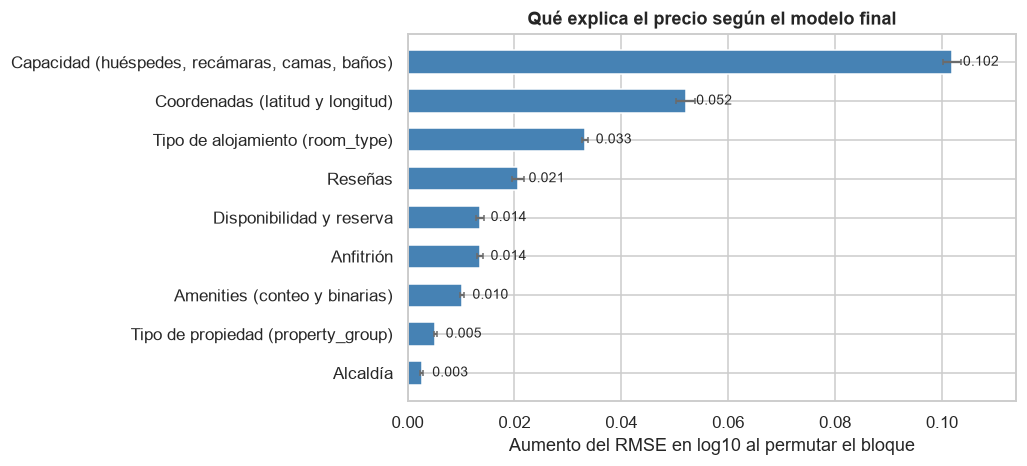

In [27]:
# Importancia por permutación en prueba. Las dummies de una misma variable se permutan juntas.
BLOQUES = {"Tipo de alojamiento (room_type)": [c for c in VARIABLES if c.startswith("room_type_")],
           "Alcaldía": [c for c in VARIABLES if c.startswith("neighbourhood_cleansed_")],
           "Tipo de propiedad (property_group)": [c for c in VARIABLES if c.startswith("property_group_")],
           "Coordenadas (latitud y longitud)": ["latitude", "longitude"],
           "Capacidad (huéspedes, recámaras, camas, baños)": ["accommodates", "bedrooms", "beds", "bathrooms"],
           "Amenities (conteo y binarias)": ["amenities_count"] + [c for c in VARIABLES if c.startswith("amen_")],
           "Reseñas": ["number_of_reviews", "reviews_per_month", "review_scores_rating", "sin_resenas"],
           "Disponibilidad y reserva": ["availability_365", "minimum_nights", "is_instant_bookable"],
           "Anfitrión": ["host_years", "host_listings_count", "host_response_rate", "host_acceptance_rate", "is_host_is_superhost",
                         "is_host_identity_verified", "verif_email", "verif_phone", "verif_work_email", "host_sin_perfil",
                         "sin_tasa_aceptacion"] + [c for c in VARIABLES if c.startswith("host_response_category_")]}
assert sorted(c for v in BLOQUES.values() for c in v) == sorted(VARIABLES), "Hay variables fuera de los bloques"

rng = np.random.default_rng(SEMILLA)
rmse_ref = np.sqrt(mean_squared_error(y_test, modelo_final.predict(X_test)))
filas = {}
for bloque_, cols in BLOQUES.items():
    aumentos = []
    for _ in range(5):
        X_perm = X_test.copy()
        X_perm[cols] = X_perm[cols].to_numpy()[rng.permutation(len(X_perm))]
        aumentos.append(np.sqrt(mean_squared_error(y_test, modelo_final.predict(X_perm))) - rmse_ref)
    filas[bloque_] = {"aumento RMSE": np.mean(aumentos), "de": np.std(aumentos, ddof=1)}
importancia = pd.DataFrame(filas).T.sort_values("aumento RMSE")
display(importancia.sort_values("aumento RMSE", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.barh(importancia.index, importancia["aumento RMSE"], xerr=importancia["de"], color=AZUL, height=0.6, error_kw={"ecolor": GRIS, "capsize": 2})
for i, v in enumerate(importancia["aumento RMSE"]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("Aumento del RMSE en log10 al permutar el bloque")
ax.set_title("Qué explica el precio según el modelo final"); ax.margins(x=0.1)
fig.tight_layout()
guardar(fig, "08_importancia_bloques.png")
plt.show()

**Figura 8. Importancia por bloques.**

- **La capacidad es lo más importante** (0.102), seguida de las **coordenadas** (0.052) y el **tipo de alojamiento** (0.033). Coincide con el EDA.
- **Alcaldía aparece muy abajo (0.003) porque las coordenadas ya contienen esa información.** La permutación solo mide lo que un bloque aporta y los demás no pueden sustituir, así que no significa que la zona no importe:
  juntas, coordenadas y alcaldía confirman que la ubicación es el segundo factor.
- **Las reseñas pesan más de lo que anticipaba su correlación** (0.021, cuando el EDA encontró correlaciones cercanas a cero). Un modelo de árboles puede aprovecharlas en combinación con otras variables.

La importancia describe lo que usa el modelo, **no una relación causal**: no indica que agregar una recámara suba el precio en cierta cantidad.

## 8. Conclusiones

**¿Hacía falta más limpieza?** Poca, y puntual: se eliminó una columna constante, se corrigieron camas y baños en 0 y recámaras incoherentes, se crearon marcas de ausencia y se excluyeron 24 precios por huésped imposibles.
Estas correcciones casi no cambian el error. Lo que sí mejora el modelo es agregar coordenadas y tasas del anfitrión, y lo que cambia la lectura de las métricas es dividir por anfitrión: una división aleatoria habría reportado un R² de 0.748 en lugar de 0.673 con el mismo modelo.

**¿Es necesario aplicar PCA, y con cuántas variables? No es necesario; se recomienda usar las 67 variables sin PCA.**

- Ninguna k mejora al modelo sin PCA. Con el modelo final, el error sube 13.4% con 59 componentes, 14.5% con 51 (95% de varianza) y 17.0% con 35 (80% de varianza).
- Si se quisiera usar PCA de todas formas, el mínimo sin pérdida apreciable sería **k = 59 con Ridge**, único caso equivalente a su versión sin PCA, pero ese modelo es claramente peor que el modelo final (RMSE 0.2125 contra 0.1821).
- En prueba, la diferencia con PCA es significativa (+12.4% de RMSE, IC 95% de la diferencia [+0.0154, +0.0293]), y sigue ahí después de reajustar sus hiperparámetros.
- **Motivos:** hay poca redundancia (solo 8 de 2,211 pares con |r| > 0.7), las variables son mayormente binarias, hay muchas más filas que variables, la varianza no coincide con la información sobre el precio, los árboles pierden al rotar los ejes y las componentes son más difíciles de explicar. Tampoco ahorra tiempo.

**Modelo final: HistGradientBoosting sin PCA, evaluado en 4,600 anuncios de anfitriones no vistos.**

| Métrica | Modelo final | Línea base (mediana) |
|---|---|---|
| RMSE log10 | 0.179 | 0.334 |
| R² log10 | 0.711 | −0.006 |
| RMSE en pesos | \$1,112 | \$1,695 |
| MAE en pesos | \$450 | \$795 |
| Error mediano en pesos | \$206 | \$487 |
| Error porcentual mediano | 22.7% | 47.3% |
| Anuncios dentro de ±20% / ±30% | 45.5% / 61.4% | 23.7% / 34.5% |
| Acierto de gama de precio (accuracy) | 72.1% | No aplica |
| Precisión promedio por gama | 72.7% | No aplica |

**Cómo usarlo y limitaciones.**

- Sirve como **referencia de precio en el centro del mercado** (\$600 a \$2,000, 19% de error mediano). No debe usarse sin revisión para anuncios de lujo o muy económicos, donde tiende a acercar el precio a la media.
- Poco más de la mitad de los anuncios queda a más de 20% de su precio real: es una orientación, no un precio exacto.
- Estima el **precio publicado**, no el precio al que realmente se reserva, y usa un solo scrape: no capta temporada ni eventos.
- Le faltan factores que seguramente influyen, como fotos, descripción, acabados o vista. Es una probable explicación del error en los anuncios de lujo, y un camino natural para mejorarlo.
- El R² en pesos (0.553) es menor que en logaritmos (0.711) porque los anuncios muy caros dominan esa métrica.